In [1]:
################# River Sediments and Seabed Changes ####################
# The purpose of this script is to (1) explore where all of the 
# river sediments end up by the end of the simulation and (2) map the
# ending seabed composition and take the difference compared to the 
# starting composition.
#
# Notes
# - This works best in xroms
# - Bed mass calculations match when using two different methods but 
#   both show an increase in total mass from rivers that appears larger
#   than the amounts provided by the rivers...so this is a bug to look into
##########################################################################

In [2]:
# Load in the packages 
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LinearSegmentedColormap
import cmocean
from shapely.geometry import Polygon
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle
import os
import matplotlib.colors as mcolors
from matplotlib import colors
from matplotlib import cm, ticker
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator, LogLocator, LogFormatterExponent, LogFormatterSciNotation, LogFormatter)
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
import cartopy.crs as ccrs
import matplotlib.ticker as tick
from matplotlib import cm, ticker
import warnings
from matplotlib.colors import LogNorm
from matplotlib.ticker import LogFormatterExponent
crs = ccrs.PlateCarree()
warnings.filterwarnings("ignore") #turns off annoying warnings
#Cartopy
land_10m = cfeature.NaturalEarthFeature('physical', 'land', '10m',
                                edgecolor='face',
                                facecolor=cfeature.COLORS['land'])

In [3]:
# set a universal fontsize 
fontsize = 20 # 32 #20

# Set the tick size for all plots
matplotlib.rc('xtick', labelsize=fontsize) 
matplotlib.rc('ytick', labelsize=fontsize)

# Prevent tick labels from overlapping
matplotlib.rcParams['xtick.major.pad'] = 12 # 28 # 12
matplotlib.rcParams['ytick.major.pad'] = 12 # 18 # 12

In [4]:
# Load in the model grid
#grid = xr.open_dataset('/Users/brun1463/Desktop/Research_Lab/Kaktovik_Alaska_2019/Code/Grids/KakAKgrd_shelf_big010_smooth006.nc') 
grid = xr.open_dataset('/projects/brun1463/ROMS/Kakak3_Alpine/Include/KakAKgrd_shelf_big010_smooth006.nc')

# Pull out some dimensions
eta_rho_len = len(grid.eta_rho)
xi_rho_len = len(grid.xi_rho)
s_rho_len = int(20)

In [5]:
# Load in the last ocean_his file 
# Unaggregated
model_output_last_unag = xr.open_dataset('/pl/active/moriarty_lab/BriannaU/Paper2/Model_Output/Unaggregated/dbsed0001_10rivs_unaggregated/ocean_his_beaufort_rivers_10rivs_13seabed_unaggregated_dbsed0001_00018.nc')
# Aggregated
model_output_last_agg = xr.open_dataset('/pl/active/moriarty_lab/BriannaU/Paper2/Model_Output/Aggregated/dbsed0001_10rivs/ocean_his_beaufort_rivers_10rivs_13seabed_aggregated_dbsed0001_00018.nc')

In [6]:
# We only looked at results until * so find that time in the model output
print(model_output_last_unag.ocean_time[-32].values)
print(model_output_last_agg.ocean_time[-32].values)

2020-10-29T21:00:00.000000000
2020-10-29T21:00:00.000000000


In [7]:
print(model_output_last_unag.ocean_time[1:4].values)
print(model_output_last_agg.ocean_time[1:4].values)

['2020-10-28T09:00:00.000000000' '2020-10-28T13:00:00.000000000'
 '2020-10-28T17:00:00.000000000']
['2020-10-28T09:00:00.000000000' '2020-10-28T13:00:00.000000000'
 '2020-10-28T17:00:00.000000000']


### Riverine Muds 

In [8]:
# Load in the river forcing file 
river_frc_std = xr.open_dataset('/projects/brun1463/ROMS/Beaufort_Shelf_Rivers_Alpine_002/Include/river_forcing_file_beaufort_shelf_10rivs_13seabed_blaskey_data_sagDSS3_rating_001.nc')


In [9]:
river_frc_std.river_transport.units

'meter3 second-1'

In [10]:
river_frc_std.river_mud_01.units

'kilogram meter-3'

In [11]:
river_frc_std.river_time[-4].values

np.datetime64('2020-10-30T01:00:00.000000000')

In [12]:
river_frc_std.river_time[1:4].values

array(['2020-07-02T01:00:00.000000000', '2020-07-03T01:00:00.000000000',
       '2020-07-04T01:00:00.000000000'], dtype='datetime64[ns]')

In [13]:
river_frc_std.river_mud_01

<xarray.DataArray 'river_mud_01' (river_time: 125, river: 17)> Size: 17kB
[2125 values with dtype=float64]
Coordinates:
  * river_time  (river_time) datetime64[ns] 1kB 2020-07-01T01:00:00 ... 2020-...
  * river       (river) float64 136B 1.0 2.0 2.0 2.0 2.0 ... 7.0 8.0 9.0 10.0
Attributes:
    long_name:  river runoff suspended sediment concentration
    time:       river_time
    units:      kilogram meter-3

In [14]:
river_frc_std.river_transport

<xarray.DataArray 'river_transport' (river_time: 125, river: 17)> Size: 17kB
[2125 values with dtype=float64]
Coordinates:
  * river_time  (river_time) datetime64[ns] 1kB 2020-07-01T01:00:00 ... 2020-...
  * river       (river) float64 136B 1.0 2.0 2.0 2.0 2.0 ... 7.0 8.0 9.0 10.0
Attributes:
    long_name:  river runoff vertically integrated mass transport
    units:      meter3 second-1
    positive:   LuvSrc=T flow in positive u,v direction, LwSrc=T flow into gr...
    negative:   LuvSrc=T flow in negative u,v direction, LwSrc=T flow out of ...
    time:       river_time

*Calculate Riverine Sediments*

In [15]:
# Make a function that takes the river input, the idnices, and returns the discharge and 
# sediemnt load for a given river
def get_river_dis_sed(river_frc, first_idx, run, seds, last_idx=2000):
    """
    The purpose of this function is to get atime series fo the river discharge
    and sediment load for a given river.
    
    Inputs:
        - river_frc: River forcing file loaded via xarray
        - first_idx: First index of the river in the forcing file (or only index if only one)
        - last_idx: Last index of the river in the forcing file
        - run: string of the run, either 'std' or 'double'
        - seds: string of if you want 'all' river sediments (agg and unag together) or 'unique' (the unique sediments)
    Outputs:
        - river_dis: Time series of river discharge for that river
        - river_sed: Tiem series of river sediment load for that river
    """
    print('first_idx: ', first_idx)
    print('last_idx: ', last_idx)
    
    # Get the transport
    # Check if the river covers multiple cells
    if (last_idx != 2000):
        # Get the discharge 
        river_dis = river_frc.river_transport[:,first_idx:last_idx+1].sum(dim='river')
        #print('river_dis shape multiple cells: ', np.shape(river_dis))
    else:
        river_dis = river_frc.river_transport[:,first_idx]
        #print('river_dis shape one cells: ', np.shape(river_dis))
    
    # Get the sediment load
    # Add together all of the sediment classes
    if run == 'std':
        if seds == 'all':
            # Unaggregated and Aggregated together 
            riv_all_ssc = (river_frc.river_sand_01 + river_frc.river_sand_02 + river_frc.river_sand_03 + 
                        river_frc.river_mud_01 + river_frc.river_mud_02 + river_frc.river_mud_03 + river_frc.river_mud_04 + 
                        river_frc.river_mud_05 + river_frc.river_mud_06 + river_frc.river_mud_07 + river_frc.river_mud_08 + 
                        river_frc.river_mud_09 + river_frc.river_mud_10 + river_frc.river_mud_11 + river_frc.river_mud_12 + 
                        river_frc.river_mud_13 + river_frc.river_mud_14 + river_frc.river_mud_15 + river_frc.river_mud_16 + 
                        river_frc.river_mud_17 + river_frc.river_mud_18 + river_frc.river_mud_19 + river_frc.river_mud_20 + 
                        river_frc.river_mud_21 + river_frc.river_mud_22 + river_frc.river_mud_23 + river_frc.river_mud_24) 
        if seds == 'unique':
            # Just the unique classes
            print(river_frc.river_mud_15[80,0].values)
            riv_all_ssc = (river_frc.river_mud_15 + river_frc.river_mud_16 + 
                        river_frc.river_mud_17 + river_frc.river_mud_18 + river_frc.river_mud_19 + river_frc.river_mud_20 + 
                        river_frc.river_mud_21 + river_frc.river_mud_22 + river_frc.river_mud_23 + river_frc.river_mud_24)
            # check if this is adding the way we expect and want
            print(riv_all_ssc[80,0].values)
    if run == 'double':
        riv_all_ssc = (river_frc.river_sand_01 + river_frc.river_sand_02 + river_frc.river_sand_03 + 
                      river_frc.river_mud_01 + river_frc.river_mud_02 + river_frc.river_mud_03 + river_frc.river_mud_04)
        
    
    # Multiply to get the load and save ssc
    if last_idx != 2000:
        river_sed = (river_frc.river_transport[:,first_idx:last_idx+1]*riv_all_ssc[:,first_idx:last_idx+1]).sum(dim='river') # kg/s
        river_ssc = riv_all_ssc[:,first_idx:last_idx+1].sum(dim='river') # kg/m3
    else:
        river_sed = (river_frc.river_transport[:,first_idx]*riv_all_ssc[:,first_idx]) # kg/s
        river_ssc = riv_all_ssc[:,first_idx] # kg/m3
        
    # Return these values
    return(river_dis, river_sed, river_ssc)


In [16]:
# Call the function for each river 
# Standard run 
water_dis_tot_std, water_sed_tot_std, water_ssc_tot_std = get_river_dis_sed(river_frc_std, 0, 'std', 'unique', -2)
water_dis_kal_std, water_sed_kal_std, water_ssc_kal_std = get_river_dis_sed(river_frc_std, 0, 'std', 'unique')
water_dis_col_std, water_sed_col_std, water_ssc_col_std = get_river_dis_sed(river_frc_std, 1, 'std', 'unique', 6)
water_dis_sag_std, water_sed_sag_std, water_ssc_sag_std = get_river_dis_sed(river_frc_std, 7, 'std', 'unique', 9)
water_dis_fis_std, water_sed_fis_std, water_ssc_fis_std = get_river_dis_sed(river_frc_std, 10, 'std', 'unique')
water_dis_kup_std, water_sed_kup_std, water_ssc_kup_std = get_river_dis_sed(river_frc_std, 11, 'std', 'unique')
water_dis_sta_std, water_sed_sta_std, water_ssc_sta_std = get_river_dis_sed(river_frc_std, 12, 'std', 'unique')
water_dis_can_std, water_sed_can_std, water_ssc_can_std = get_river_dis_sed(river_frc_std, 13, 'std', 'unique')
water_dis_kat_std, water_sed_kat_std, water_ssc_kat_std = get_river_dis_sed(river_frc_std, 14, 'std', 'unique')
water_dis_hul_std, water_sed_hul_std, water_ssc_hul_std = get_river_dis_sed(river_frc_std, 15, 'std', 'unique')
water_dis_jag_std, water_sed_jag_std, water_ssc_jag_std = get_river_dis_sed(river_frc_std, 16, 'std', 'unique')


first_idx:  0
last_idx:  -2
4.560263121576485e-05
4.560263121576485e-05
first_idx:  0
last_idx:  2000
4.560263121576485e-05
4.560263121576485e-05
first_idx:  1
last_idx:  6
4.560263121576485e-05
4.560263121576485e-05
first_idx:  7
last_idx:  9
4.560263121576485e-05
4.560263121576485e-05
first_idx:  10
last_idx:  2000
4.560263121576485e-05
4.560263121576485e-05
first_idx:  11
last_idx:  2000
4.560263121576485e-05
4.560263121576485e-05
first_idx:  12
last_idx:  2000
4.560263121576485e-05
4.560263121576485e-05
first_idx:  13
last_idx:  2000
4.560263121576485e-05
4.560263121576485e-05
first_idx:  14
last_idx:  2000
4.560263121576485e-05
4.560263121576485e-05
first_idx:  15
last_idx:  2000
4.560263121576485e-05
4.560263121576485e-05
first_idx:  16
last_idx:  2000
4.560263121576485e-05
4.560263121576485e-05


In [17]:
# Compare total to another method 
#water_sed_col_std
col_sed_check = (river_frc_std.river_transport[:,1:7]*river_frc_std.river_mud_16[:,1:7]).sum(dim='river')
print(np.shape(col_sed_check))
print(col_sed_check[:5].values)
print(water_sed_col_std[:5].values)

(125,)
[19.38579371 18.60984627 18.3678043  17.1130309  13.82421954]
[19.38579371 18.60984627 18.3678043  17.1130309  13.82421954]


In [18]:
np.shape(water_sed_kal_std)

(125,)

In [19]:
# Now we have the kg/s of sediment from each river but want the total
# Set delta time for model output
delta_time = 86400 # 86400 seconds = 1 day (frequency of river inputs); 14400 seconds = 4 hours 

# Set last time index
last_time_idx = -4

# Multiply the river sediment load (kg/s) by s to get total kgs
print(np.shape(water_sed_kal_std))
kal_sed_kg = water_sed_kal_std * delta_time # kg
print(np.shape(kal_sed_kg))
col_sed_kg = water_sed_col_std * delta_time
sag_sed_kg = water_sed_sag_std * delta_time
fis_sed_kg = water_sed_fis_std * delta_time
kup_sed_kg = water_sed_kup_std * delta_time
sta_sed_kg = water_sed_sta_std * delta_time
can_sed_kg = water_sed_can_std * delta_time
kat_sed_kg = water_sed_kat_std * delta_time
hul_sed_kg = water_sed_hul_std * delta_time
jag_sed_kg = water_sed_jag_std * delta_time

# Multiply each river sed by this delta time
kal_tot_sed_kg = np.cumsum(kal_sed_kg[:last_time_idx])
col_tot_sed_kg = np.cumsum(col_sed_kg[:last_time_idx])
sag_tot_sed_kg = np.cumsum(sag_sed_kg[:last_time_idx])
fis_tot_sed_kg = np.cumsum(fis_sed_kg[:last_time_idx])
kup_tot_sed_kg = np.cumsum(kup_sed_kg[:last_time_idx])
sta_tot_sed_kg = np.cumsum(sta_sed_kg[:last_time_idx])
can_tot_sed_kg = np.cumsum(can_sed_kg[:last_time_idx])
kat_tot_sed_kg = np.cumsum(kat_sed_kg[:last_time_idx])
hul_tot_sed_kg = np.cumsum(hul_sed_kg[:last_time_idx])
jag_tot_sed_kg = np.cumsum(jag_sed_kg[:last_time_idx])


(125,)
(125,)


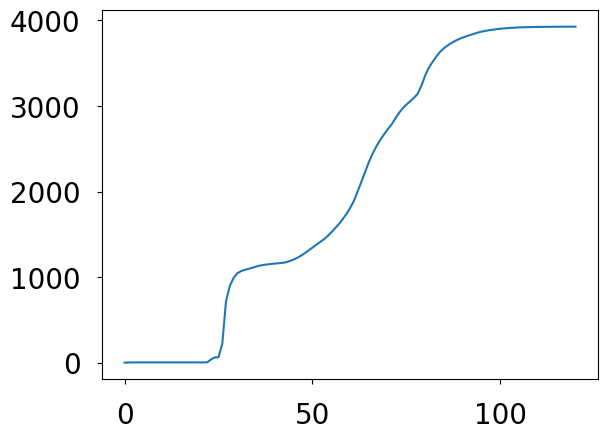

In [20]:
plt.plot(kal_tot_sed_kg)

In [21]:
kal_tot_sed_kg[-1].values

array(3925.93944036)

*Calculate Bed Sediments*

In [22]:
model_output_last_agg.bed_thickness

<xarray.DataArray 'bed_thickness' (ocean_time: 42, Nbed: 11, eta_rho: 206,
                                   xi_rho: 608)> Size: 463MB
[57864576 values with dtype=float64]
Coordinates:
    lon_rho     (eta_rho, xi_rho) float64 1MB ...
    lat_rho     (eta_rho, xi_rho) float64 1MB ...
  * ocean_time  (ocean_time) datetime64[ns] 336B 2020-10-28T05:00:00 ... 2020...
Dimensions without coordinates: Nbed, eta_rho, xi_rho
Attributes:
    long_name:  sediment bed layer thickness
    units:      meter
    time:       ocean_time
    grid:       grid
    location:   face
    field:      bed_thickness, scalar, series

In [23]:
model_output_last_agg.mudmass_16

<xarray.DataArray 'mudmass_16' (ocean_time: 42, Nbed: 11, eta_rho: 206,
                                xi_rho: 608)> Size: 463MB
[57864576 values with dtype=float64]
Coordinates:
    lon_rho     (eta_rho, xi_rho) float64 1MB ...
    lat_rho     (eta_rho, xi_rho) float64 1MB ...
  * ocean_time  (ocean_time) datetime64[ns] 336B 2020-10-28T05:00:00 ... 2020...
Dimensions without coordinates: Nbed, eta_rho, xi_rho
Attributes:
    long_name:   cohesive sediment mass, size class 16
    size_class:  time dependent �
��Q��?
    units:       kilogram meter-2
    time:        ocean_time
    grid:        grid
    location:    face
    field:       mudmass_16, scalar, series

In [24]:
# Mudmass in the seabed is units of kg/m2 so get area of seabed to multiply by 
dx_bed = 750 # m
dy_bed = 600 # m


Method 1: Using mdumass

In [25]:
# Now get the different amounts from each river in the seabed
# Unaggregated 
kal_tot_sed_seabed_unag = (model_output_last_unag.mudmass_15[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
col_tot_sed_seabed_unag = (model_output_last_unag.mudmass_16[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
sag_tot_sed_seabed_unag = (model_output_last_unag.mudmass_17[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
fis_tot_sed_seabed_unag = (model_output_last_unag.mudmass_18[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
kup_tot_sed_seabed_unag = (model_output_last_unag.mudmass_19[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
sta_tot_sed_seabed_unag = (model_output_last_unag.mudmass_20[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
can_tot_sed_seabed_unag = (model_output_last_unag.mudmass_21[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
kat_tot_sed_seabed_unag = (model_output_last_unag.mudmass_22[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
hul_tot_sed_seabed_unag = (model_output_last_unag.mudmass_23[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
jag_tot_sed_seabed_unag = (model_output_last_unag.mudmass_24[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])

# Aggregated 
kal_tot_sed_seabed_agg = (model_output_last_agg.mudmass_15[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
col_tot_sed_seabed_agg = (model_output_last_agg.mudmass_16[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
sag_tot_sed_seabed_agg = (model_output_last_agg.mudmass_17[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
fis_tot_sed_seabed_agg = (model_output_last_agg.mudmass_18[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
kup_tot_sed_seabed_agg = (model_output_last_agg.mudmass_19[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
sta_tot_sed_seabed_agg = (model_output_last_agg.mudmass_20[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
can_tot_sed_seabed_agg = (model_output_last_agg.mudmass_21[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
kat_tot_sed_seabed_agg = (model_output_last_agg.mudmass_22[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
hul_tot_sed_seabed_agg = (model_output_last_agg.mudmass_23[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])
jag_tot_sed_seabed_agg = (model_output_last_agg.mudmass_24[-32,:,:,:]*dx_bed*dy_bed).sum(dim=['Nbed', 'eta_rho', 'xi_rho'])

Method 2: Calculating with bed_thickness, mudfrac, porosity, sediment density, dx, dy

In [26]:
# Print porosity and density to check
print(model_output_last_agg.poros[:].values)
print(model_output_last_agg.grain_density[-32,200,200].values)

[0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7
 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7 0.7]
2649.999999999998


In [27]:
# Try another way that is mudfrac*porosity
# Pull out porosity 
poros = 0.7 # model_output_last_agg.poros[0].values # 0.7
grain_dens = 2650 # kg/m3

# Do the calculations
col_sed_seabed_unag_check = np.empty((len(model_output_last_unag.Nbed.values), len(grid.eta_rho), len(grid.xi_rho)))
print(np.shape(col_sed_seabed_unag_check))
# Loop through seabed to make sure it does this (loop is not needed, you get same number without it)
for n in range(len(model_output_last_unag.Nbed)):  
    #print('n: ', n) 
    col_sed_seabed_unag_check[n,:,:] = dx_bed * dy_bed * model_output_last_unag.bed_thickness[-32,n,:,:] * (1 - poros) * grain_dens * model_output_last_unag.mudfrac_16[-32,n,:,:]
    #print('check: ', col_sed_seabed_unag_check[n,100,200])
print(np.shape(col_sed_seabed_unag_check))

# Take sum
col_tot_sed_seabed_unag_check = np.nansum(col_sed_seabed_unag_check)
# Check with value calculated above
print((col_tot_sed_seabed_unag_check))
print(col_tot_sed_seabed_unag.values)

(11, 206, 608)
(11, 206, 608)
35189004.32064317
35189004.32064316


In [28]:
# Get the sums per seabed layer
print(np.nansum(col_sed_seabed_unag_check[0,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[1,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[2,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[3,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[4,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[5,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[6,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[7,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[8,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[9,:,:], axis=(0,1)))
print(np.nansum(col_sed_seabed_unag_check[10,:,:], axis=(0,1))) # Somehow the bottom seabed layer has accumulated a lot of sediment from the Colville...?

2357137.4833683386
3012225.0802180287
2704608.4303461383
2186986.113262946
2000268.5870567807
1825093.5146485125
1695142.7530660427
1620697.0182060306
1445195.4475415982
1020043.7393134619
15321606.15361527


In [29]:
# Check the largest value
print(np.nanmax(col_sed_seabed_unag_check[10,:,:]))
print(np.where((col_sed_seabed_unag_check[10,:,:] == 1353649.8356169197)))
print(np.nanmax(model_output_last_unag.mudfrac_16[-32,10,:,:]))

1353649.8356169197
(array([36]), array([168]))
0.0031965487369610603


In [30]:
print(model_output_last_unag.mudfrac_16[-32,10,36,168].values)
print(model_output_last_unag.bed_thickness[-32,10,36,168].values)
print(model_output_last_unag.mudfrac_16[-32,10,36,168].values * model_output_last_unag.bed_thickness[-32,10,36,168].values)

0.0031965487369610603
1.1837101239544328
0.003783787101654562


*Calculate Sediments in Water*

In [31]:
# Get volume of the cells to multiply by concentrations; # dz has been triple checked 
dx = 750 # m
dy = 600 # m
dz = abs(model_output_last_unag.z_w[-32,:-1,:,:].values - model_output_last_unag.z_w[-32,1:,:,:].values)
grid_vol = dx * dy * dz
print(np.shape(grid_vol))

(20, 206, 608)


In [32]:
# Get the total mass in the water column at the last time step
# Unaggregated 
kal_tot_sed_water_unag = (model_output_last_unag.mud_15[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
col_tot_sed_water_unag = (model_output_last_unag.mud_16[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
sag_tot_sed_water_unag = (model_output_last_unag.mud_17[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
fis_tot_sed_water_unag = (model_output_last_unag.mud_18[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
kup_tot_sed_water_unag = (model_output_last_unag.mud_19[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
sta_tot_sed_water_unag = (model_output_last_unag.mud_20[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
can_tot_sed_water_unag = (model_output_last_unag.mud_21[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
kat_tot_sed_water_unag = (model_output_last_unag.mud_22[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
hul_tot_sed_water_unag = (model_output_last_unag.mud_23[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
jag_tot_sed_water_unag = (model_output_last_unag.mud_24[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])

# Aggregated
kal_tot_sed_water_agg = (model_output_last_agg.mud_15[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
col_tot_sed_water_agg = (model_output_last_agg.mud_16[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
sag_tot_sed_water_agg = (model_output_last_agg.mud_17[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
fis_tot_sed_water_agg = (model_output_last_agg.mud_18[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
kup_tot_sed_water_agg = (model_output_last_agg.mud_19[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
sta_tot_sed_water_agg = (model_output_last_agg.mud_20[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
can_tot_sed_water_agg = (model_output_last_agg.mud_21[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
kat_tot_sed_water_agg = (model_output_last_agg.mud_22[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
hul_tot_sed_water_agg = (model_output_last_agg.mud_23[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])
jag_tot_sed_water_agg = (model_output_last_agg.mud_24[-32,:,:,:]*grid_vol).sum(dim=['s_rho', 'eta_rho', 'xi_rho'])


*Print All the Things*

In [33]:
# Make a function to get fractions and print 
def calculate_print_percent_riv_seabed_water(river_name, river_tot, river_bed, river_water):
    """
    This function takes the river name, total river sediment at certain time, 
    mass in bed, and mass in water at that same time and prints out percentages and
    totals.

    Inputs:
    - river_name: string of river name, 'Kalikpik'
    - river_tot: total mass of sediment from that river 
                    received at same time as other inputs (kg)
    - river_bed: total mass of river sed in the seabed at certain time (kg)
    - river_water: total mass of river sed in the water at certain time (kg)
    """

    # Get the ratios

    # Print stuff
    print(river_name)
    print('Total Unique kg Delivered: ', river_tot.values)
    print('Total Unique kg Bed (*broken*): ', river_bed.values)
    print('Total Unique kg Water: ', river_water.values)
    print('Percent in Seabed (*broken*): ', (river_bed/river_tot).values*100)
    print('Percent in Water: ', (river_water/river_tot).values*100)
    print('Percent Unaccounted for (*broken*): ', (100-(((river_bed/river_tot).values*100) + ((river_water/river_tot).values*100))))



In [34]:
# Now print the total, percen in bed, and percent in water for each river
# on October 30
print('Unaggregated')
calculate_print_percent_riv_seabed_water('Kalikpik', kal_tot_sed_kg[-1], kal_tot_sed_seabed_unag, kal_tot_sed_water_unag)
calculate_print_percent_riv_seabed_water('Colville', col_tot_sed_kg[-1], col_tot_sed_seabed_unag, col_tot_sed_water_unag)
calculate_print_percent_riv_seabed_water('Sagavanirktok', sag_tot_sed_kg[-1], sag_tot_sed_seabed_unag, sag_tot_sed_water_unag)
calculate_print_percent_riv_seabed_water('Fish Creek', fis_tot_sed_kg[-1], fis_tot_sed_seabed_unag, fis_tot_sed_water_unag)
calculate_print_percent_riv_seabed_water('Kuparuk', kup_tot_sed_kg[-1], kup_tot_sed_seabed_unag, kup_tot_sed_water_unag)



Unaggregated
Kalikpik
Total Unique kg Delivered:  3925.939440361219
Total Unique kg Bed (*broken*):  63.78848352001388
Total Unique kg Water:  0.10374844213241619
Percent in Seabed (*broken*):  1.6247954021966473
Percent in Water:  0.0026426399008047476
Percent Unaccounted for (*broken*):  98.37256195790255
Colville
Total Unique kg Delivered:  31201327.825012367
Total Unique kg Bed (*broken*):  35189004.32064316
Total Unique kg Water:  221836.94638220087
Percent in Seabed (*broken*):  112.78047049149649
Percent in Water:  0.710985595312923
Percent Unaccounted for (*broken*):  -13.491456086809407
Sagavanirktok
Total Unique kg Delivered:  4035195.4381336444
Total Unique kg Bed (*broken*):  6922971.201628754
Total Unique kg Water:  86530.48369922118
Percent in Seabed (*broken*):  171.56470628918933
Percent in Water:  2.1443938720163502
Percent Unaccounted for (*broken*):  -73.70910016120567
Fish Creek
Total Unique kg Delivered:  8737830.145965924
Total Unique kg Bed (*broken*):  326645.07

In [35]:
# Print more 
print('Unaggregated')
calculate_print_percent_riv_seabed_water('Staines', sta_tot_sed_kg[-1], sta_tot_sed_seabed_unag, sta_tot_sed_water_unag)
calculate_print_percent_riv_seabed_water('Canning', can_tot_sed_kg[-1], can_tot_sed_seabed_unag, can_tot_sed_water_unag)
calculate_print_percent_riv_seabed_water('Katakturuk', kat_tot_sed_kg[-1], kat_tot_sed_seabed_unag, kat_tot_sed_water_unag)
calculate_print_percent_riv_seabed_water('Hulahula', hul_tot_sed_kg[-1], hul_tot_sed_seabed_unag, hul_tot_sed_water_unag)
calculate_print_percent_riv_seabed_water('Jago', jag_tot_sed_kg[-1], jag_tot_sed_seabed_unag, jag_tot_sed_water_unag)

Unaggregated
Staines
Total Unique kg Delivered:  4877813.257850283
Total Unique kg Bed (*broken*):  6652557.231204889
Total Unique kg Water:  332700.4247696839
Percent in Seabed (*broken*):  136.38400815156996
Percent in Water:  6.820688025197369
Percent Unaccounted for (*broken*):  -43.20469617676733
Canning
Total Unique kg Delivered:  7805.761401848621
Total Unique kg Bed (*broken*):  9434.348328167922
Total Unique kg Water:  557.7444258580358
Percent in Seabed (*broken*):  120.86390862438617
Percent in Water:  7.14529175495867
Percent Unaccounted for (*broken*):  -28.009200379344833
Katakturuk
Total Unique kg Delivered:  380.17715785817336
Total Unique kg Bed (*broken*):  125.16334660605882
Total Unique kg Water:  8.02788398465823
Percent in Seabed (*broken*):  32.92237421921901
Percent in Water:  2.111616602608478
Percent Unaccounted for (*broken*):  64.96600917817251
Hulahula
Total Unique kg Delivered:  54438.47979860829
Total Unique kg Bed (*broken*):  44414.77561564152
Total Uni

In [36]:
print('Aggregated')
calculate_print_percent_riv_seabed_water('Kalikpik', kal_tot_sed_kg[-1], kal_tot_sed_seabed_agg, kal_tot_sed_water_agg)
calculate_print_percent_riv_seabed_water('Colville', col_tot_sed_kg[-1], col_tot_sed_seabed_agg, col_tot_sed_water_agg)
calculate_print_percent_riv_seabed_water('Sagavanirktok', sag_tot_sed_kg[-1], sag_tot_sed_seabed_agg, sag_tot_sed_water_agg)
calculate_print_percent_riv_seabed_water('Fish Creek', fis_tot_sed_kg[-1], fis_tot_sed_seabed_agg, fis_tot_sed_water_agg)
calculate_print_percent_riv_seabed_water('Kuparuk', kup_tot_sed_kg[-1], kup_tot_sed_seabed_agg, kup_tot_sed_water_agg)

Aggregated
Kalikpik
Total Unique kg Delivered:  3925.939440361219
Total Unique kg Bed (*broken*):  64.08812929790943
Total Unique kg Water:  0.0007054694210607372
Percent in Seabed (*broken*):  1.6324278627184527
Percent in Water:  1.7969442264138137e-05
Percent Unaccounted for (*broken*):  98.36755416783929
Colville
Total Unique kg Delivered:  31201327.825012367
Total Unique kg Bed (*broken*):  37437156.003006496
Total Unique kg Water:  87.37413912181927
Percent in Seabed (*broken*):  119.98577821100041
Percent in Water:  0.00028003339989837316
Percent Unaccounted for (*broken*):  -19.98605824440031
Sagavanirktok
Total Unique kg Delivered:  4035195.4381336444
Total Unique kg Bed (*broken*):  7091521.1660343
Total Unique kg Water:  1741.6159521699376
Percent in Seabed (*broken*):  175.7417025955567
Percent in Water:  0.043160634444399264
Percent Unaccounted for (*broken*):  -75.7848632300011
Fish Creek
Total Unique kg Delivered:  8737830.145965924
Total Unique kg Bed (*broken*):  34832

In [37]:
# Print more 
print('Aggregated')
calculate_print_percent_riv_seabed_water('Staines', sta_tot_sed_kg[-1], sta_tot_sed_seabed_agg, sta_tot_sed_water_agg)
calculate_print_percent_riv_seabed_water('Canning', can_tot_sed_kg[-1], can_tot_sed_seabed_agg, can_tot_sed_water_agg)
calculate_print_percent_riv_seabed_water('Katakturuk', kat_tot_sed_kg[-1], kat_tot_sed_seabed_agg, kat_tot_sed_water_agg)
calculate_print_percent_riv_seabed_water('Hulahula', hul_tot_sed_kg[-1], hul_tot_sed_seabed_agg, hul_tot_sed_water_agg)
calculate_print_percent_riv_seabed_water('Jago', jag_tot_sed_kg[-1], jag_tot_sed_seabed_agg, jag_tot_sed_water_agg)

Aggregated
Staines
Total Unique kg Delivered:  4877813.257850283
Total Unique kg Bed (*broken*):  7175570.429810999
Total Unique kg Water:  615.1415461989429
Percent in Seabed (*broken*):  147.1062964180258
Percent in Water:  0.0126110105836656
Percent Unaccounted for (*broken*):  -47.118907428609475
Canning
Total Unique kg Delivered:  7805.761401848621
Total Unique kg Bed (*broken*):  10283.070303458355
Total Unique kg Water:  0.30159833003616493
Percent in Seabed (*broken*):  131.73692832864504
Percent in Water:  0.0038637913011886076
Percent Unaccounted for (*broken*):  -31.740792119946235
Katakturuk
Total Unique kg Delivered:  380.17715785817336
Total Unique kg Bed (*broken*):  141.21588018785752
Total Unique kg Water:  8.745589275617603e-05
Percent in Seabed (*broken*):  37.14475666645356
Percent in Water:  2.3003984050194252e-05
Percent Unaccounted for (*broken*):  62.85522032956239
Hulahula
Total Unique kg Delivered:  54438.47979860829
Total Unique kg Bed (*broken*):  78573.8890

### Seabed Starting vs Ending Composition

In [38]:
# Load in the initial conditions file
#ini_conds = xr.open_dataset('/Users/brun1463/Desktop/Research_Lab/Beaufort_Shelf_Rivers_proj_002/Model_Input/Initial_Conds/initial_conds_beaufort_shelf_10rivs_13sections_2020_001.nc') # restrat_mix_ini_kaktovik_biggrid013.nc
ini_conds = xr.open_dataset('/projects/brun1463/ROMS/Beaufort_Shelf_Rivers_Alpine_002/Include/initial_conds_beaufort_shelf_10rivs_13sections_2020_001.nc')

In [39]:
# Make it so land can be masked easily 
# Make it so land will be gray
temp_mask = grid.mask_rho.values
temp_mask = np.where(temp_mask==0, np.nan, temp_mask)

In [40]:
# Get the starting ratios
# Add together the percentages of the two mud classes - check this since might need to add more classes together to get full mud fraction...
# Muds
tot_mud_percent_start = (ini_conds.mudfrac_01 + ini_conds.mudfrac_02 + ini_conds.mudfrac_03 + ini_conds.mudfrac_04 + ini_conds.mudfrac_05 +
                  ini_conds.mudfrac_06 + ini_conds.mudfrac_07 + ini_conds.mudfrac_08 + ini_conds.mudfrac_09 + ini_conds.mudfrac_10 +
                  ini_conds.mudfrac_11 + ini_conds.mudfrac_12 + ini_conds.mudfrac_13 + ini_conds.mudfrac_14)

tot_mud_percent_wland_start = tot_mud_percent_start * temp_mask

# Sands
# Add together the percentages of the two mud classes
tot_sand_percent_start = ini_conds.sandfrac_01 + ini_conds.sandfrac_02

tot_sand_percent_wland_start = tot_sand_percent_start * temp_mask

In [41]:
# Get the Endings ratios
# Muds
tot_mud_percent_end = (model_output_last_unag.mudfrac_01[-32,:,:,:] + model_output_last_unag.mudfrac_02[-32,:,:,:] + model_output_last_unag.mudfrac_03[-32,:,:,:] + model_output_last_unag.mudfrac_04[-32,:,:,:] + model_output_last_unag.mudfrac_05[-32,:,:,:] +
                  model_output_last_unag.mudfrac_06[-32,:,:,:] + model_output_last_unag.mudfrac_07[-32,:,:,:] + model_output_last_unag.mudfrac_08[-32,:,:,:] + model_output_last_unag.mudfrac_09[-32,:,:,:] + model_output_last_unag.mudfrac_10[-32,:,:,:] +
                  model_output_last_unag.mudfrac_11[-32,:,:,:] + model_output_last_unag.mudfrac_12[-32,:,:,:] + model_output_last_unag.mudfrac_13[-32,:,:,:] + model_output_last_unag.mudfrac_14[-32,:,:,:])

tot_mud_percent_wland_end = tot_mud_percent_end * temp_mask
#tot_mud_percent_wland_end.compute()

# Sands
# Add together the percentages of the two mud classes
tot_sand_percent_end = model_output_last_unag.sandfrac_01[-32,:,:,:] + model_output_last_unag.sandfrac_02[-32,:,:,:]

tot_sand_percent_wland_end = tot_sand_percent_end * temp_mask
#tot_sand_percent_wland_end.compute()

In [42]:
river_marker_colors = ['#FC440F', '#F5ED00', '#5EF38C', '#26532B', '#F43ECF', '#9C00A8',
                       '#0115F5', '#00A6A6', '#AB64EB', '#D44179', '#08E0E3', '#B27009', '#EA8D40']

Text(0.962, 0.072, 'b)')

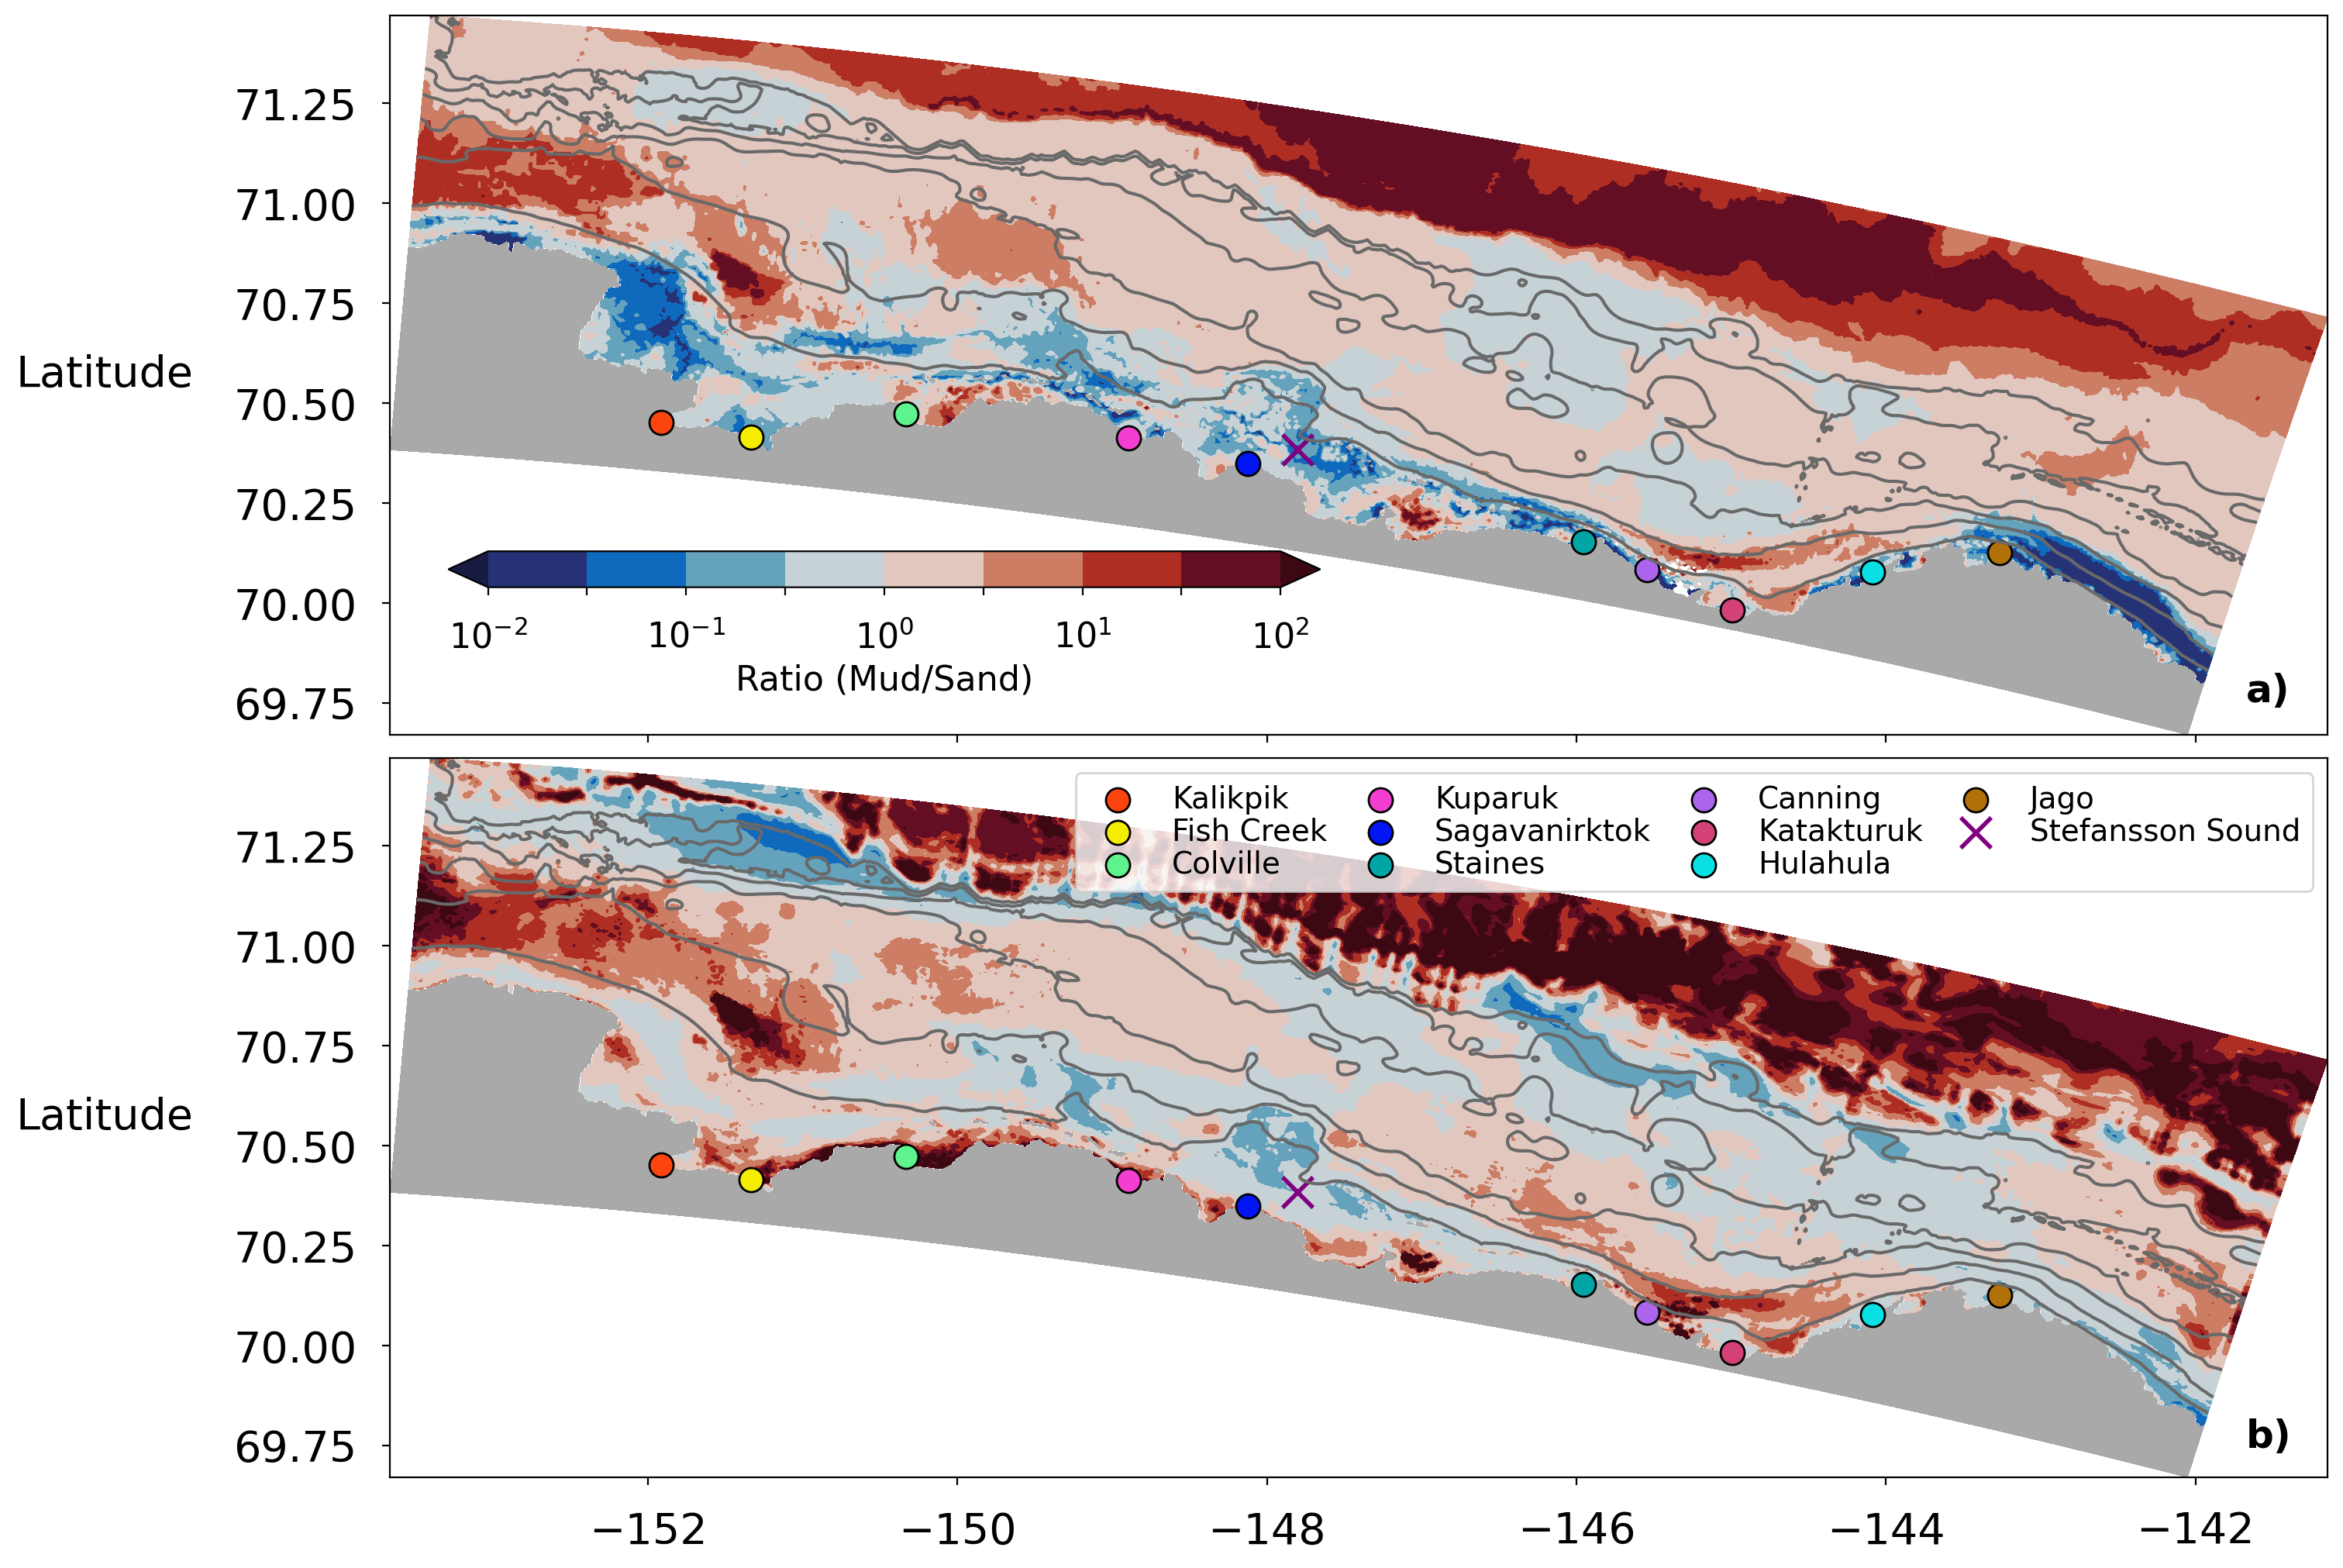

In [43]:
# Make plot after the model domain plot in the paper 
# Same plot as above but without bed shear stress panel
# Set the levels
lev_bathy = np.arange(0,101,1)
lev_bathy2 = np.arange(0,70,10)

# Plot land as gray 
# Make reverse mask so land can be gray 
reverse_colors = colors.ListedColormap(['darkgray','#FF000000'])
bounds=[0,1,2]
norm = colors.BoundaryNorm(bounds, reverse_colors.N)
# Make new mask so land is gray - NEW
mask_rho2 = grid.mask_rho.values
mask_rho2[mask_rho2==1.0] = 2.0

# Set levels
lev2 = [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
lev2b = [10**(-2), 10**(-1.5), 10**(-1), 10**(-0.5), 10**(0), 10**(0.5), 10**(1), 10**(1.5), 10**(2)]

# Make the figure
fig2, ax2 = plt.subplots(2, figsize=(15,10), gridspec_kw={'height_ratios': [1, 1]}, # (15,8)
                         dpi=200, constrained_layout=True) # (width, height), (15, 12) for horizontal colorbar; (20, 16) for vertical colorbaroutside plots


# ----- Top Subplot: Starting Composition -----
# Plot the bathymetry
cs1 = ax2[0].contour(grid.lon_rho.values, grid.lat_rho.values, grid.h[:,:].values, lev_bathy2, colors='dimgray', projection=crs)
# Plot land as gray 
cs0g = ax2[0].contourf(grid.lon_rho.values, grid.lat_rho.values, mask_rho2, cmap=reverse_colors, norm=norm, projection=crs)
# Plot the ratio 
cmap1 = cmocean.cm.balance
# cmap1.set_under('darkgray')
# cmap1.set_bad('darkgray')

ratio_mud_over_sand_start = (tot_mud_percent_wland_start/tot_sand_percent_wland_start)

# Get rid of zeros before logging
no_inf1_start = np.where(ratio_mud_over_sand_start == 0, 10**-1.5, ratio_mud_over_sand_start)
# Mask land
#ratio_mud_over_sand_wland = ratio_mud_over_sand * temp_mask
ratio_mud_over_sand_wland_start = no_inf1_start * temp_mask
# Get rid of infinity 
no_inf2_start = np.where(ratio_mud_over_sand_wland_start == np.inf, 40, ratio_mud_over_sand_wland_start)

# No log scale
#cs13 = ax4[2].contourf(grid.lon_rho.values, grid.lat_rho.values, ratio_mud_over_sand_wland[0,0,:,:], lev9,
 #                     cmap=cmap5, extend='both', label='Ratio')
# Log of actual values
log_ratio_start = np.log10(no_inf2_start[0,0,:,:])
log_ratio2_start = np.nan_to_num(log_ratio_start, nan=-3)
# Works but might be wrong since real values are -2 to 2
#cs13 = ax4[2].contourf(grid.lon_rho.values, grid.lat_rho.values, log_ratio2, 
 #                     lev13, cmap=cmap5,  vmin=-2.0, vmax=2.0, extend='both', label='Ratio')
# Try plotting just the ratio but on a log scale 
cs1 = ax2[0].contourf(grid.lon_rho.values, grid.lat_rho.values, no_inf2_start[0,0,:,:], 
                      lev2b, cmap=cmap1, locator=LogLocator(base=10), vmin=10**(-2), 
                      vmax=10**(2), extend='both', label='Ratio', projection=crs)
# Plot colorbar
# Bottom left
cbar1 = fig2.colorbar(cs1, label='Ratio (Mud/Sand)', orientation='horizontal', ax=ax2[1], 
                      cax=ax2[0].inset_axes((0.03, 0.205, 0.45, 0.05)), extend='both')
cbar1.set_label(label='Ratio (Mud/Sand)', size=fontsize-4, color='black')
cbar1.ax.tick_params(labelcolor='black', labelsize=fontsize-4)
# Format axes
#ax1[0].set_xlabel('Longitude (degrees)', fontsize=fontsize)
ax2[0].set_ylabel('Latitude \n(degrees)', fontsize=fontsize, rotation=0, labelpad=60, va='center') #118

# ----- Middle Subplot: Fraction of Mud/Sand -----
#ax2b = fig2.add_subplot(gs[1, 0], projection=ccrs.PlateCarree())
# Determine spacing of contours
lev7 = np.arange(-0.00001, 1, 0.01)
cmap4 = cmocean.cm.turbid
cmap4.set_under('darkgray')

lev8 = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

lev9 = np.arange(0,2,0.01)

# Plot bathymetry contours
# Plot the bathymetry
cs9 = ax2[1].contour(grid.lon_rho.values, grid.lat_rho.values, grid.h[:,:].values, lev_bathy2, colors='dimgray', projection=crs)
# Plot land as gray 
cs0g = ax2[1].contourf(grid.lon_rho.values, grid.lat_rho.values, mask_rho2, cmap=reverse_colors, norm=norm, projection=crs)

# Plot the Ending ratio 
ratio_mud_over_sand_end = (tot_mud_percent_wland_end/tot_sand_percent_wland_end)

# Get rid of zeros before logging
no_inf1_end = np.where(ratio_mud_over_sand_end == 0, 10**-1.5, ratio_mud_over_sand_end)

# Mask land
#ratio_mud_over_sand_wland = ratio_mud_over_sand * temp_mask
ratio_mud_over_sand_wland_end = no_inf1_end * temp_mask
#input('press enter...')

# Get rid of nans
#ratio_mud_over_sand_wland = ratio_mud_over_sand_wland.fillna(-1.5)

# Get rid of infinity 
no_inf2_end = np.where(ratio_mud_over_sand_wland_end == np.inf, 40, ratio_mud_over_sand_wland_end)

# No log scale
#cs13 = ax4[2].contourf(grid.lon_rho.values, grid.lat_rho.values, ratio_mud_over_sand_wland[0,0,:,:], lev9,
 #                     cmap=cmap5, extend='both', label='Ratio')
 
# Log of actual values
log_ratio_end = np.log10(no_inf2_end[0,:,:])
log_ratio2_end = np.nan_to_num(log_ratio_end, nan=-3)
# Works but might be wrong since real values are -2 to 2
#cs13 = ax4[2].contourf(grid.lon_rho.values, grid.lat_rho.values, log_ratio2, 
 #                     lev13, cmap=cmap5,  vmin=-2.0, vmax=2.0, extend='both', label='Ratio')
# Try plotting just the ratio but on a log scale 
cs2 = ax2[1].contourf(grid.lon_rho.values, grid.lat_rho.values, no_inf2_end[0,:,:], 
                      lev2b, cmap=cmap1, locator=LogLocator(base=10), vmin=10**(-2), 
                      vmax=10**(2), extend='both', label='Ratio', projection=crs)

# Log scale
# Data as log
# Top right
#cbar6 = fig2.colorbar(cs13, label='Ratio (Mud/Sand)', orientation='horizontal', ax=ax2[1], 
 #                     cax=ax2[1].inset_axes((0.55, 0.92, 0.45, 0.05)), extend='both')
# # Bottom left
# cbar2 = fig2.colorbar(cs2, label='Ratio (Mud/Sand)', orientation='horizontal', ax=ax2[1], 
#                       cax=ax2[1].inset_axes((0.03, 0.205, 0.45, 0.05)), extend='both')
# cbar2.set_label(label='Ratio (Mud/Sand)', size=fontsize-4, color='black')
# cbar2.ax.tick_params(labelcolor='black', labelsize=fontsize-4)


# Loop through axes and add rivers
for t in range(2):
    #ax2 = [ax2a, ax2b]
    # Plot the 10 rivers in the grid
    # Go from West to East
    # Kalikpik River
    eta_kal_idx = 23 #22
    xi_kal_idx = 87
    s1 = ax2[t].scatter(grid.lon_rho[eta_kal_idx, xi_kal_idx].values, grid.lat_rho[eta_kal_idx, xi_kal_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[0], label='Kalikpik')

    # Fish Creek
    eta_fis_idx = 20
    xi_fis_idx = 117 #116
    s2 = ax2[t].scatter(grid.lon_rho[eta_fis_idx, xi_fis_idx].values, grid.lat_rho[eta_fis_idx, xi_fis_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[1], label='Fish Creek')

    # Colville River
    eta_col_idx = 39
    xi_col_idx = 166 #166
    s3 = ax2[t].scatter(grid.lon_rho[eta_col_idx, xi_col_idx].values, grid.lat_rho[eta_col_idx, xi_col_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[2], label='Colville')

    # Kuparik
    # Kukpuk - Change this to be labeled as the Kuparuk since it  is actually the main channel 
    # of the Kuparuk River
    eta_kuk_idx = 41 #40
    xi_kuk_idx = 239
    eta_kup_idx = 41 #40
    xi_kup_idx = 242
    s5 = ax2[t].scatter(grid.lon_rho[eta_kuk_idx, xi_kuk_idx].values, grid.lat_rho[eta_kuk_idx, xi_kuk_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[4], label='Kuparuk')

    # Sagavanirktok River
    eta_sag_idx = 37 #36
    xi_sag_idx = 279
    s9 = ax2[t].scatter(grid.lon_rho[eta_sag_idx, xi_sag_idx].values, grid.lat_rho[eta_sag_idx, xi_sag_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[6], label='Sagavanirktok')

    # Canning River
    # Staines River
    eta_sta_idx = 27 #26
    xi_sta_idx = 393
    s10 = ax2[t].scatter(grid.lon_rho[eta_sta_idx, xi_sta_idx].values, grid.lat_rho[eta_sta_idx, xi_sta_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[7], label='Staines')

    # Canning River
    eta_can_idx = 20 #19
    xi_can_idx = 416
    s11 = ax2[t].scatter(grid.lon_rho[eta_can_idx, xi_can_idx].values, grid.lat_rho[eta_can_idx, xi_can_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[8], label='Canning')

    # Katakturuk River
    eta_kat_idx = 9 #8
    xi_kat_idx = 447
    s12 = ax2[t].scatter(grid.lon_rho[eta_kat_idx, xi_kat_idx].values, grid.lat_rho[eta_kat_idx, xi_kat_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[9], label='Katakturuk')

    # Hulahula River
    eta_hul_idx = 40
    xi_hul_idx = 489
    s13 = ax2[t].scatter(grid.lon_rho[eta_hul_idx, xi_hul_idx].values, grid.lat_rho[eta_hul_idx, xi_hul_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[10], label='Hulahula')

    # Jago River
    eta_jag_idx = 62 #61
    xi_jag_idx = 528
    s14 = ax2[t].scatter(grid.lon_rho[eta_jag_idx, xi_jag_idx].values, grid.lat_rho[eta_jag_idx, xi_jag_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[11], label='Jago')
    
    # Plot Stefansson Sound
    # Set the indices
    eta_boulder_idx = 47
    xi_boulder_idx = 294
    ax2[t].scatter(grid.lon_rho[eta_boulder_idx, xi_boulder_idx].values, grid.lat_rho[eta_boulder_idx, xi_boulder_idx].values, 
                    marker='x', s=200, linewidth=2, edgecolors='violet', color='purple', label='Stefansson Sound')
    
# Add a legend for all the rivers
# Temporary not too bad legend
#ax2[0].legend(loc='lower left', ncol=4, fontsize=14, columnspacing=0.75, labelspacing=0.1)
ax2[1].legend(loc='upper right', ncol=4, fontsize=14, columnspacing=0.75, labelspacing=0.1)
    

# Mute x-axis labels on middle plots
plt.setp(ax2[0].get_xticklabels(), visible=False)
#plt.setp(ax2[1].get_xticklabels(), visible=False)

# Adjust spacing between subplots
plt.subplots_adjust(hspace=0.05) #0.08 # (0.22, 0.25)

# Label the axes
ax2[0].set_ylabel('Latitude', fontsize=fontsize, rotation=0, labelpad=60, va='center') #118
ax2[1].set_ylabel('Latitude', fontsize=fontsize, rotation=0, labelpad=60, va='center') #118


# Add subplot labels
fig2.text(0.962, 0.553, 'a)', color='black', fontsize=fontsize-2, weight='bold')
fig2.text(0.962, 0.072, 'b)', color='black', fontsize=fontsize-2, weight='bold')

In [44]:
print(np.nanmax(tot_mud_percent_wland_end.values))
print(np.nanmin(tot_mud_percent_wland_end.values))
print(np.nanmax(tot_sand_percent_wland_end.values))
print(np.nanmin(tot_sand_percent_wland_end.values))

0.9999981150372292
0.0
0.9900990099009902
0.0


In [45]:
np.nanmax(no_inf2_end)

np.float64(2595127930213417.0)

Text(0.962, 0.072, 'b)')

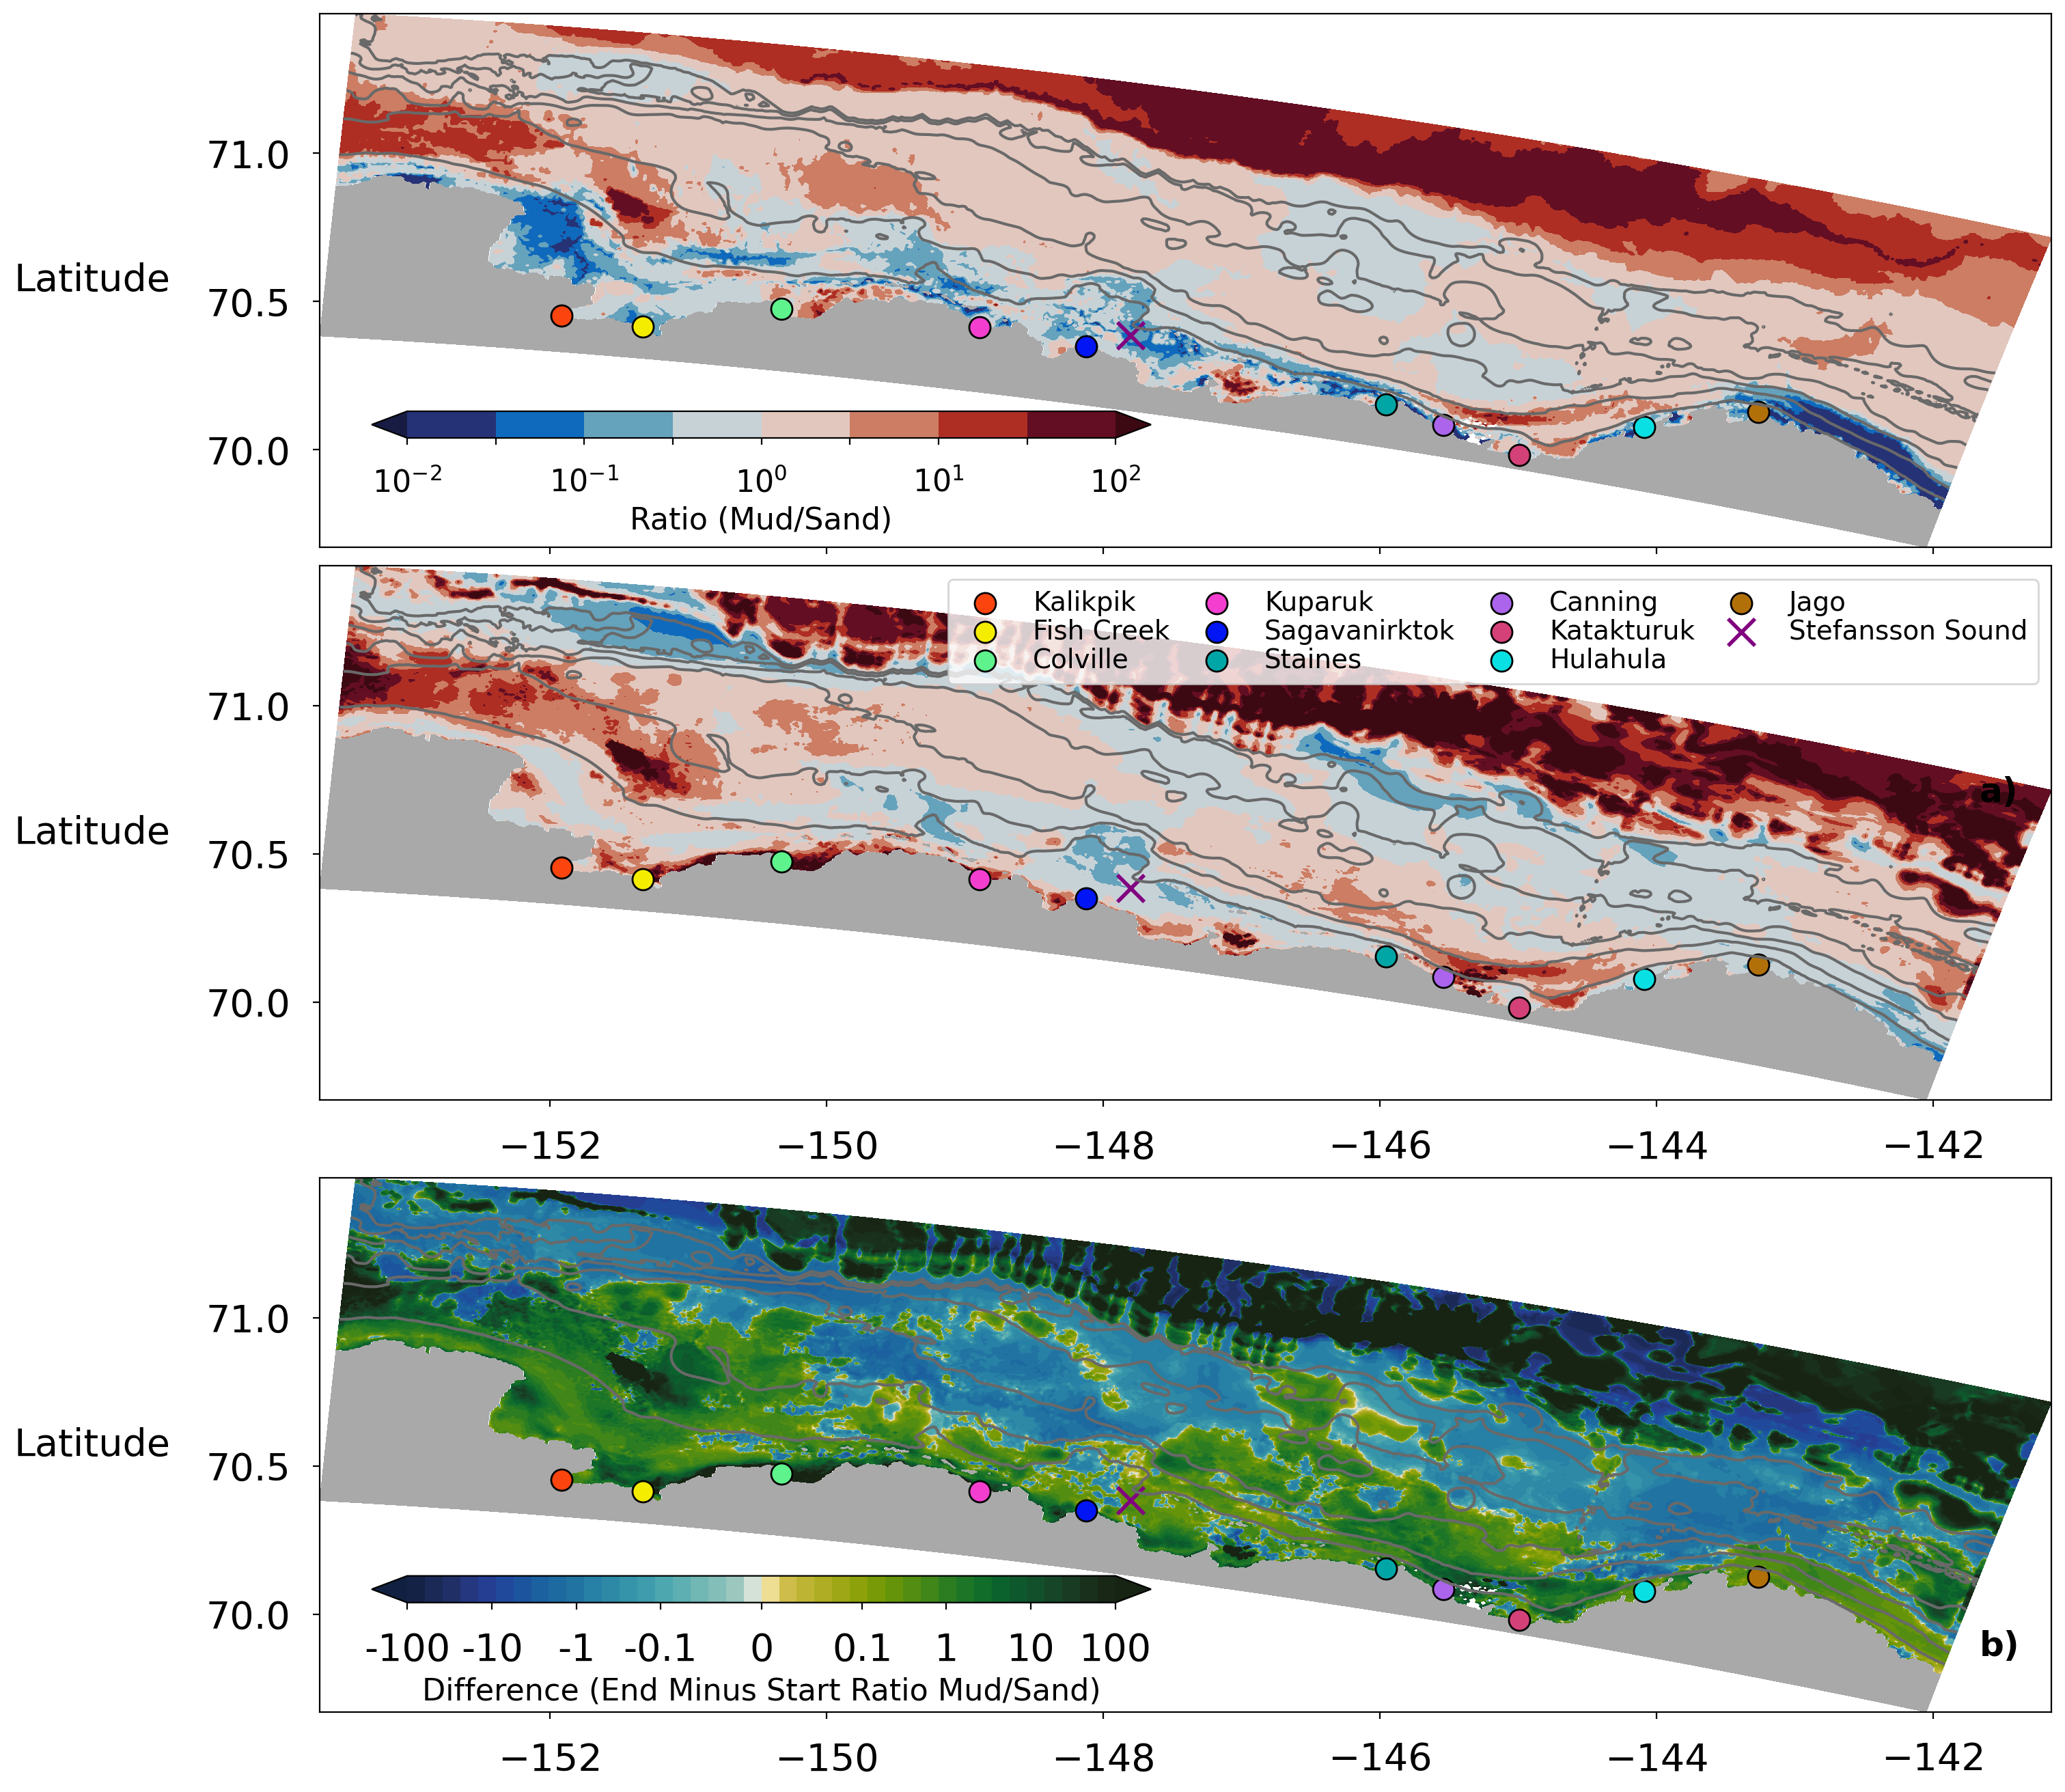

In [46]:
# Make another version that also has the difference 
# Make the figure
fig2, ax2 = plt.subplots(3, figsize=(15,13), gridspec_kw={'height_ratios': [1, 1, 1]}, # (15,8)
                         dpi=200, constrained_layout=True) # (width, height), (15, 12) for horizontal colorbar; (20, 16) for vertical colorbaroutside plots


# ----- Top Subplot: Starting Composition -----
# Plot the bathymetry
cs1 = ax2[0].contour(grid.lon_rho.values, grid.lat_rho.values, grid.h[:,:].values, lev_bathy2, colors='dimgray', projection=crs)
# Plot land as gray 
cs0g = ax2[0].contourf(grid.lon_rho.values, grid.lat_rho.values, mask_rho2, cmap=reverse_colors, norm=norm, projection=crs)
# Plot the ratio 
cmap1 = cmocean.cm.balance
# Try plotting just the ratio but on a log scale 
cs1 = ax2[0].contourf(grid.lon_rho.values, grid.lat_rho.values, no_inf2_start[0,0,:,:], 
                      lev2b, cmap=cmap1, locator=LogLocator(base=10), vmin=10**(-2), 
                      vmax=10**(2), extend='both', label='Ratio', projection=crs)
# Plot colorbar
# Bottom left
cbar1 = fig2.colorbar(cs1, label='Ratio (Mud/Sand)', orientation='horizontal', ax=ax2[1], 
                      cax=ax2[0].inset_axes((0.03, 0.205, 0.45, 0.05)), extend='both')
cbar1.set_label(label='Ratio (Mud/Sand)', size=fontsize-4, color='black')
cbar1.ax.tick_params(labelcolor='black', labelsize=fontsize-4)
# Format axes
#ax1[0].set_xlabel('Longitude (degrees)', fontsize=fontsize)
ax2[0].set_ylabel('Latitude \n(degrees)', fontsize=fontsize, rotation=0, labelpad=60, va='center') #118

# ----- Middle Subplot: Fraction of Mud/Sand End -----
#ax2b = fig2.add_subplot(gs[1, 0], projection=ccrs.PlateCarree())
# Determine spacing of contours
lev7 = np.arange(-0.00001, 1, 0.01)

lev8 = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

lev9 = np.arange(0,2,0.01)

# Plot bathymetry contours
# Plot the bathymetry
cs9 = ax2[1].contour(grid.lon_rho.values, grid.lat_rho.values, grid.h[:,:].values, lev_bathy2, colors='dimgray', projection=crs)
# Plot land as gray 
cs0g = ax2[1].contourf(grid.lon_rho.values, grid.lat_rho.values, mask_rho2, cmap=reverse_colors, norm=norm, projection=crs)
# Try plotting just the ratio but on a log scale 
cs2 = ax2[1].contourf(grid.lon_rho.values, grid.lat_rho.values, no_inf2_end[0,:,:], 
                      lev2b, cmap=cmap1, locator=LogLocator(base=10), vmin=10**(-2), 
                      vmax=10**(2), extend='both', label='Ratio', projection=crs)

# Log scale
# Data as log
# Top right
#cbar6 = fig2.colorbar(cs13, label='Ratio (Mud/Sand)', orientation='horizontal', ax=ax2[1], 
 #                     cax=ax2[1].inset_axes((0.55, 0.92, 0.45, 0.05)), extend='both')
# # Bottom left
# cbar2 = fig2.colorbar(cs2, label='Ratio (Mud/Sand)', orientation='horizontal', ax=ax2[1], 
#                       cax=ax2[1].inset_axes((0.03, 0.205, 0.45, 0.05)), extend='both')
# cbar2.set_label(label='Ratio (Mud/Sand)', size=fontsize-4, color='black')
# cbar2.ax.tick_params(labelcolor='black', labelsize=fontsize-4)

# ----- Bottom Subplot: Fraction of Mud/Sand Difference -----
# Plot the difference (end minus start)
cmap_diff = cmocean.cm.delta
# Plot the bathymetry
cs4 = ax2[2].contour(grid.lon_rho.values, grid.lat_rho.values, grid.h[:,:].values, lev_bathy2, colors='dimgray', projection=crs)
# Plot land as gray 
cs0g = ax2[2].contourf(grid.lon_rho.values, grid.lat_rho.values, mask_rho2, cmap=reverse_colors, norm=norm, projection=crs)
# Try plotting just the ratio but on a log scale 
# cs5 = ax2[2].contourf(grid.lon_rho.values, grid.lat_rho.values, no_inf2_end[0,:,:]-no_inf2_start[0,0,:,:], 
#                       lev2b, cmap=cmap_diff, locator=LogLocator(base=10), vmin=-10**(2), 
#                       vmax=10*(2), extend='both', label='Ratio', projection=crs)
lev_diff = np.concatenate([-np.logspace(2, -2, 20), [0], np.logspace(-2, 2, 20)])
cs5 = ax2[2].contourf(grid.lon_rho.values, grid.lat_rho.values, no_inf2_end[0,:,:]-no_inf2_start[0,0,:,:], 
                      lev_diff, cmap=cmap_diff, norm=matplotlib.colors.SymLogNorm(linthresh=0.01, linscale=1, vmin=-100,vmax=100,base=10), 
                      extend='both', label='Ratio', projection=crs)

#ax2[2].scatter(grid.lon_rho[100,300].values, grid.lat_rho[100,300].values, color='red', marker='x', s=200)
# Plot colorbar
# Bottom left
cbar3 = fig2.colorbar(cs5, label='Ratio (Mud/Sand)', orientation='horizontal', ax=ax2[2], 
                      cax=ax2[2].inset_axes((0.03, 0.205, 0.45, 0.05)), extend='both')
cbar3.set_ticks([-100, -10, -1, -0.1, 0, 0.1, 1, 10, 100])
cbar3.set_ticklabels(['-100', '-10', '-1', '-0.1', '0', '0.1', '1', '10', '100'])
cbar3.set_label(label='Difference (End Minus Start Ratio Mud/Sand)', size=fontsize-4, color='black')

# Loop through axes and add rivers
for t in range(3):
    #ax2 = [ax2a, ax2b]
    # Plot the 10 rivers in the grid
    # Go from West to East
    # Kalikpik River
    eta_kal_idx = 23 #22
    xi_kal_idx = 87
    s1 = ax2[t].scatter(grid.lon_rho[eta_kal_idx, xi_kal_idx].values, grid.lat_rho[eta_kal_idx, xi_kal_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[0], label='Kalikpik')

    # Fish Creek
    eta_fis_idx = 20
    xi_fis_idx = 117 #116
    s2 = ax2[t].scatter(grid.lon_rho[eta_fis_idx, xi_fis_idx].values, grid.lat_rho[eta_fis_idx, xi_fis_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[1], label='Fish Creek')

    # Colville River
    eta_col_idx = 39
    xi_col_idx = 166 #166
    s3 = ax2[t].scatter(grid.lon_rho[eta_col_idx, xi_col_idx].values, grid.lat_rho[eta_col_idx, xi_col_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[2], label='Colville')

    # Kuparik
    # Kukpuk - Change this to be labeled as the Kuparuk since it  is actually the main channel 
    # of the Kuparuk River
    eta_kuk_idx = 41 #40
    xi_kuk_idx = 239
    eta_kup_idx = 41 #40
    xi_kup_idx = 242
    s5 = ax2[t].scatter(grid.lon_rho[eta_kuk_idx, xi_kuk_idx].values, grid.lat_rho[eta_kuk_idx, xi_kuk_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[4], label='Kuparuk')

    # Sagavanirktok River
    eta_sag_idx = 37 #36
    xi_sag_idx = 279
    s9 = ax2[t].scatter(grid.lon_rho[eta_sag_idx, xi_sag_idx].values, grid.lat_rho[eta_sag_idx, xi_sag_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[6], label='Sagavanirktok')

    # Canning River
    # Staines River
    eta_sta_idx = 27 #26
    xi_sta_idx = 393
    s10 = ax2[t].scatter(grid.lon_rho[eta_sta_idx, xi_sta_idx].values, grid.lat_rho[eta_sta_idx, xi_sta_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[7], label='Staines')

    # Canning River
    eta_can_idx = 20 #19
    xi_can_idx = 416
    s11 = ax2[t].scatter(grid.lon_rho[eta_can_idx, xi_can_idx].values, grid.lat_rho[eta_can_idx, xi_can_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[8], label='Canning')

    # Katakturuk River
    eta_kat_idx = 9 #8
    xi_kat_idx = 447
    s12 = ax2[t].scatter(grid.lon_rho[eta_kat_idx, xi_kat_idx].values, grid.lat_rho[eta_kat_idx, xi_kat_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[9], label='Katakturuk')

    # Hulahula River
    eta_hul_idx = 40
    xi_hul_idx = 489
    s13 = ax2[t].scatter(grid.lon_rho[eta_hul_idx, xi_hul_idx].values, grid.lat_rho[eta_hul_idx, xi_hul_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[10], label='Hulahula')

    # Jago River
    eta_jag_idx = 62 #61
    xi_jag_idx = 528
    s14 = ax2[t].scatter(grid.lon_rho[eta_jag_idx, xi_jag_idx].values, grid.lat_rho[eta_jag_idx, xi_jag_idx].values, 
                marker='.', s=500, linewidth=1, edgecolors='black', color=river_marker_colors[11], label='Jago')
    
    # Plot Stefansson Sound
    # Set the indices
    eta_boulder_idx = 47
    xi_boulder_idx = 294
    ax2[t].scatter(grid.lon_rho[eta_boulder_idx, xi_boulder_idx].values, grid.lat_rho[eta_boulder_idx, xi_boulder_idx].values, 
                    marker='x', s=200, linewidth=2, edgecolors='violet', color='purple', label='Stefansson Sound')
    
# Add a legend for all the rivers
# Temporary not too bad legend
#ax2[0].legend(loc='lower left', ncol=4, fontsize=14, columnspacing=0.75, labelspacing=0.1)
ax2[1].legend(loc='upper right', ncol=4, fontsize=14, columnspacing=0.75, labelspacing=0.1)
    

# Mute x-axis labels on middle plots
plt.setp(ax2[0].get_xticklabels(), visible=False)
#plt.setp(ax2[1].get_xticklabels(), visible=False)

# Adjust spacing between subplots
plt.subplots_adjust(hspace=0.05) #0.08 # (0.22, 0.25)

# Label the axes
ax2[0].set_ylabel('Latitude', fontsize=fontsize, rotation=0, labelpad=60, va='center') #118
ax2[1].set_ylabel('Latitude', fontsize=fontsize, rotation=0, labelpad=60, va='center') #118
ax2[2].set_ylabel('Latitude', fontsize=fontsize, rotation=0, labelpad=60, va='center') #118

# Add subplot labels
fig2.text(0.962, 0.553, 'a)', color='black', fontsize=fontsize-2, weight='bold')
fig2.text(0.962, 0.072, 'b)', color='black', fontsize=fontsize-2, weight='bold')

Green means muddier (or less sandy) at the end and blue means sandier (or less muddy) at the end

In [47]:
print(np.nanmin(no_inf2_end[0,:,:]-no_inf2_start[0,0,:,:]))
print(np.nanmax(no_inf2_end[0,:,:]-no_inf2_start[0,0,:,:]))
print((no_inf2_end[0,100,300]-no_inf2_start[0,0,100,300]))

-47.839924943996806
4729643655384.793
-0.25322479427025857


### Look Closlier at the Seabed Weirdness

In [72]:
# Load in all of the model output
# Unaggregated (to start)
model_output_unag = xr.open_mfdataset('/pl/active/moriarty_lab/BriannaU/Paper2/Model_Output/Unaggregated/dbsed0001_10rivs_unaggregated/ocean_his_beaufort_rivers_10rivs_13seabed_unaggregated_dbsed0001_*.nc')


In [73]:
# Load in the post-processed data to work with instead to plot
river_sed_seabed_water_unag = xr.open_dataset('/projects/brun1463/ROMS/river_sed_seabed_water_timeseries_unag.nc')
river_sed_seabed_water_agg = xr.open_dataset('/projects/brun1463/ROMS/river_sed_seabed_water_timeseries_agg.nc')

In [74]:
river_sed_seabed_water_agg

<xarray.Dataset> Size: 131kB
Dimensions:                      (ocean_time: 781)
Coordinates:
  * ocean_time                   (ocean_time) datetime64[ns] 6kB 2020-07-01T0...
Data variables: (12/20)
    kal_tot_sed_seabed_agg_full  (ocean_time) float64 6kB ...
    kal_tot_sed_water_agg_full   (ocean_time) float64 6kB ...
    col_tot_sed_seabed_agg_full  (ocean_time) float64 6kB ...
    col_tot_sed_water_agg_full   (ocean_time) float64 6kB ...
    sag_tot_sed_seabed_agg_full  (ocean_time) float64 6kB ...
    sag_tot_sed_water_agg_full   (ocean_time) float64 6kB ...
    ...                           ...
    kat_tot_sed_seabed_agg_full  (ocean_time) float64 6kB ...
    kat_tot_sed_water_agg_full   (ocean_time) float64 6kB ...
    hul_tot_sed_seabed_agg_full  (ocean_time) float64 6kB ...
    hul_tot_sed_water_agg_full   (ocean_time) float64 6kB ...
    jag_tot_sed_seabed_agg_full  (ocean_time) float64 6kB ...
    jag_tot_sed_water_agg_full   (ocean_time) float64 6kB ...
Attributes:
    description:  Time series of riverine aggregated muds in the water column...

In [75]:
print(model_output_unag.ocean_time[725].values)

2020-10-29T21:00:00.000000000


In [76]:
model_output_unag.dep_net

<xarray.DataArray 'dep_net' (ocean_time: 759, eta_rho: 206, xi_rho: 608)> Size: 761MB
dask.array<concatenate, shape=(759, 206, 608), dtype=float64, chunksize=(43, 206, 608), chunktype=numpy.ndarray>
Coordinates:
    lon_rho     (eta_rho, xi_rho) float64 1MB dask.array<chunksize=(206, 608), meta=np.ndarray>
    lat_rho     (eta_rho, xi_rho) float64 1MB dask.array<chunksize=(206, 608), meta=np.ndarray>
  * ocean_time  (ocean_time) datetime64[ns] 6kB 2020-07-01T01:00:00 ... 2020-...
Dimensions without coordinates: eta_rho, xi_rho
Attributes:
    long_name:  erosion or deposition
    units:      meter
    time:       ocean_time
    grid:       grid
    location:   face
    field:      dep_net, scalar, series

In [77]:
# Calculate net deposition/erosion and plot it 
net_erosion = np.cumsum(model_output_unag.dep_net, axis=(0))

In [78]:
net_erosion

<xarray.DataArray 'dep_net' (ocean_time: 759, eta_rho: 206, xi_rho: 608)> Size: 761MB
dask.array<nancumsum, shape=(759, 206, 608), dtype=float64, chunksize=(43, 206, 608), chunktype=numpy.ndarray>
Coordinates:
    lon_rho     (eta_rho, xi_rho) float64 1MB dask.array<chunksize=(206, 608), meta=np.ndarray>
    lat_rho     (eta_rho, xi_rho) float64 1MB dask.array<chunksize=(206, 608), meta=np.ndarray>
  * ocean_time  (ocean_time) datetime64[ns] 6kB 2020-07-01T01:00:00 ... 2020-...
Dimensions without coordinates: eta_rho, xi_rho

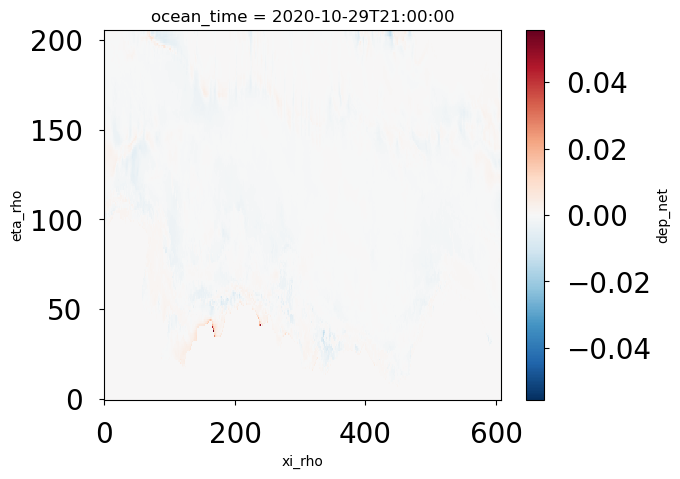

In [79]:
# Plot this 
net_erosion[725,:,:].plot()

In [80]:
model_output_unag.bed_thickness

<xarray.DataArray 'bed_thickness' (ocean_time: 759, Nbed: 11, eta_rho: 206,
                                   xi_rho: 608)> Size: 8GB
dask.array<concatenate, shape=(759, 11, 206, 608), dtype=float64, chunksize=(43, 11, 206, 608), chunktype=numpy.ndarray>
Coordinates:
    lon_rho     (eta_rho, xi_rho) float64 1MB dask.array<chunksize=(206, 608), meta=np.ndarray>
    lat_rho     (eta_rho, xi_rho) float64 1MB dask.array<chunksize=(206, 608), meta=np.ndarray>
  * ocean_time  (ocean_time) datetime64[ns] 6kB 2020-07-01T01:00:00 ... 2020-...
Dimensions without coordinates: Nbed, eta_rho, xi_rho
Attributes:
    long_name:  sediment bed layer thickness
    units:      meter
    time:       ocean_time
    grid:       grid
    location:   face
    field:      bed_thickness, scalar, series

In [81]:
tot_bed_thick_end = model_output_unag.bed_thickness[725,:,:,:].sum(dim=['Nbed'])


In [82]:
print(np.min(tot_bed_thick_end.values))
print(np.max(tot_bed_thick_end.values))
print(np.mean(tot_bed_thick_end.values))

0.0
1.2031292852242437
0.7982412760071674


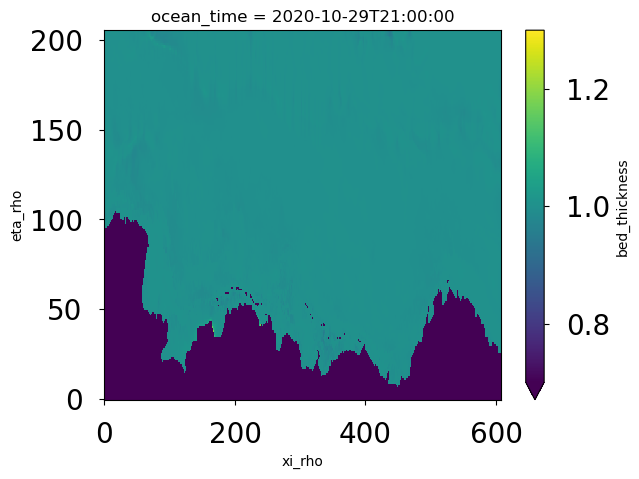

In [83]:
tot_bed_thick_end.plot(vmin=0.7, vmax=1.3)

*Look at Timeseries Changes*

Text(0, 0.5, 'Mass (kg)')

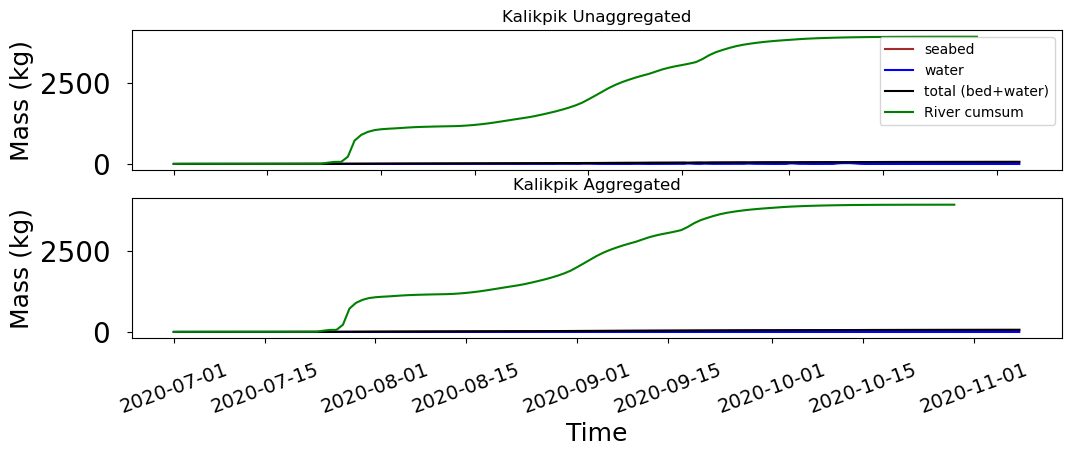

In [87]:
# Make time series, one per river, of total sediment 
# from that river delivered (cumsum), amount in seabed, 
# and amount in water
# Kalikpik
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kal_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kal_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.kal_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.kal_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, kal_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Kalikpik Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kal_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kal_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.kal_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.kal_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, kal_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Kalikpik Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

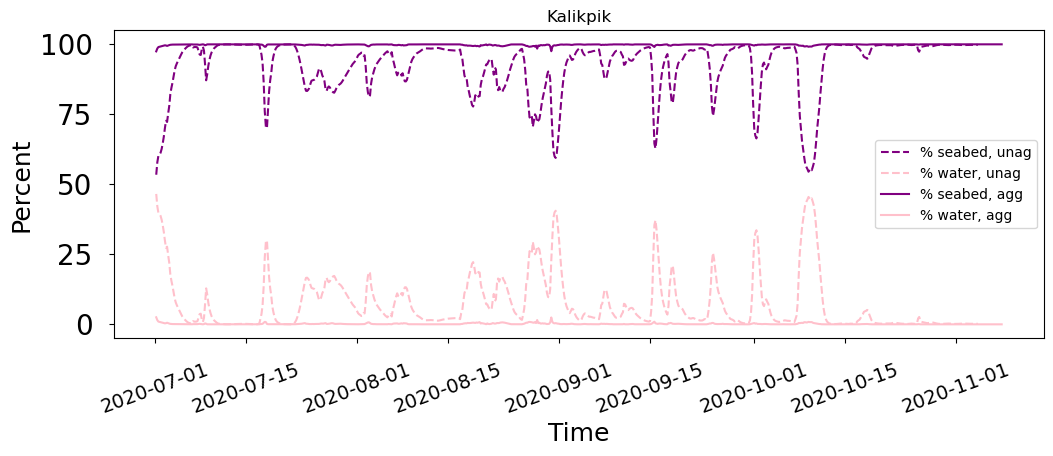

In [107]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Note: This is not total percent over time but just the 
# percent at each time step of the amount that is in the domain at that time step
# Bri think about how to look at totals instead...do cumsum of model output
# for the values above? (for mass in seabed and water column...we have total 
# at each time step but do we want cumulative total, too?)
# Calculate total
kal_tot_from_output_unag = (river_sed_seabed_water_unag.kal_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.kal_tot_sed_water_unag_full)
kal_tot_from_output_agg = (river_sed_seabed_water_agg.kal_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.kal_tot_sed_water_agg_full)

# Kalikpik
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kal_tot_sed_seabed_unag_full/kal_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kal_tot_sed_water_unag_full/kal_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kal_tot_sed_seabed_agg_full/kal_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kal_tot_sed_water_agg_full/kal_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Kalikpik')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)



Text(0, 0.5, 'Mass (kg)')

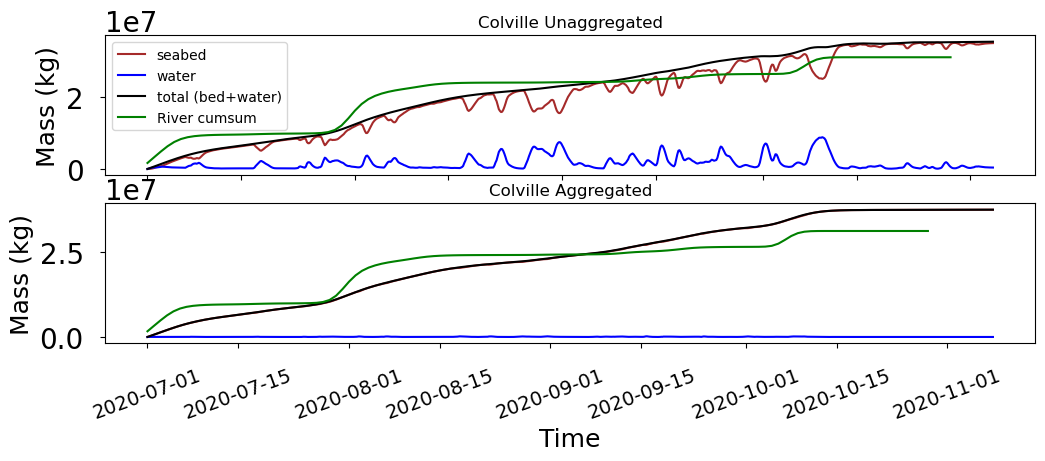

In [108]:
# Same above but for Colville
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.col_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.col_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.col_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.col_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, col_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Colville Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.col_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.col_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.col_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.col_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, col_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Colville Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

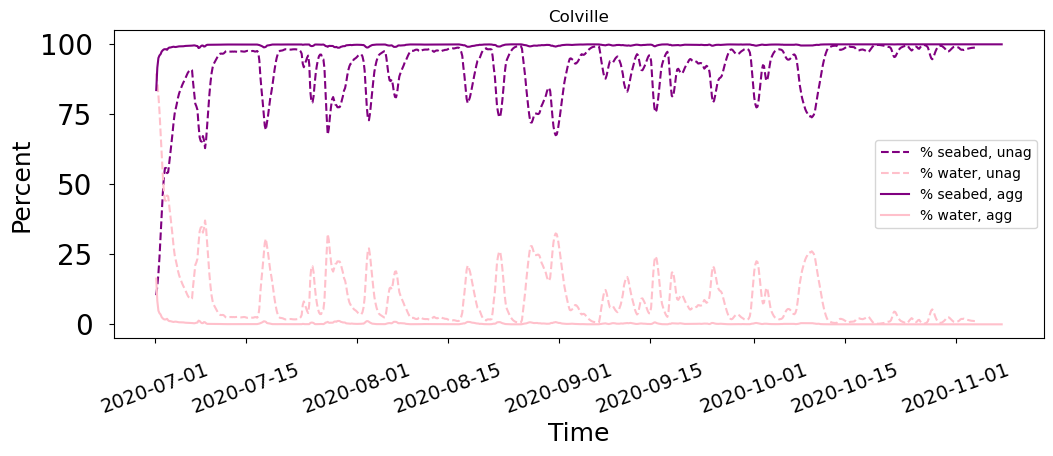

In [109]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Calculate total
col_tot_from_output_unag = (river_sed_seabed_water_unag.col_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.col_tot_sed_water_unag_full)
col_tot_from_output_agg = (river_sed_seabed_water_agg.col_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.col_tot_sed_water_agg_full)

# Colville
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.col_tot_sed_seabed_unag_full/col_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.col_tot_sed_water_unag_full/col_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.col_tot_sed_seabed_agg_full/col_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.col_tot_sed_water_agg_full/col_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Colville')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)

Text(0, 0.5, 'Mass (kg)')

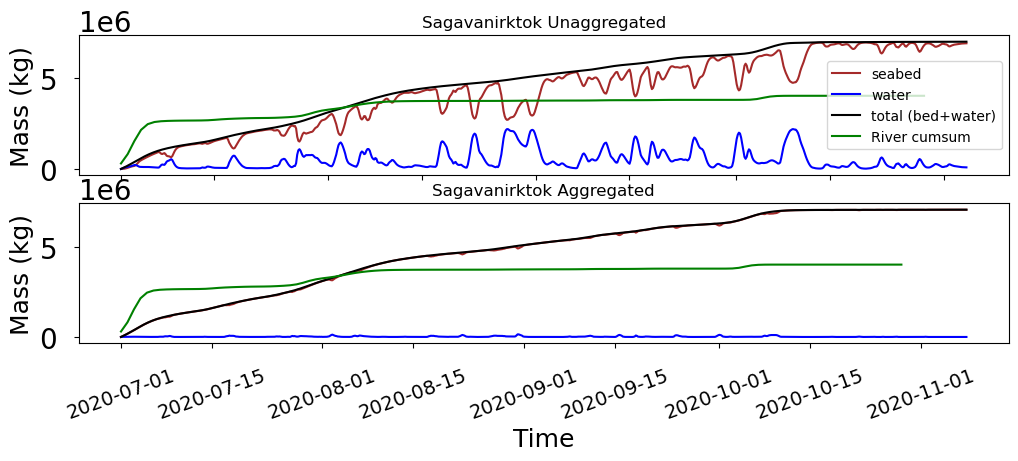

In [110]:
# Sagavanirktok
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.sag_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.sag_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.sag_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.sag_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, sag_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Sagavanirktok Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.sag_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.sag_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.sag_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.sag_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, sag_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Sagavanirktok Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

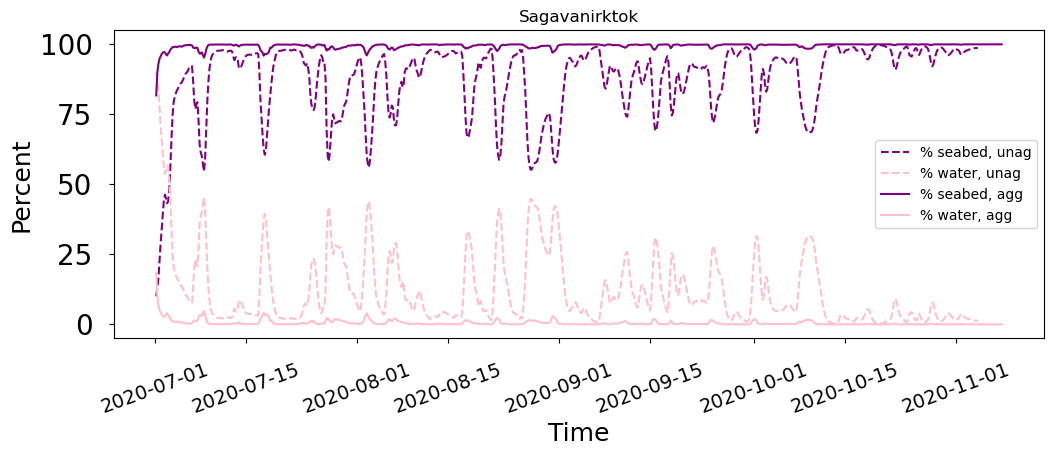

In [111]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Calculate total
sag_tot_from_output_unag = (river_sed_seabed_water_unag.sag_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.sag_tot_sed_water_unag_full)
sag_tot_from_output_agg = (river_sed_seabed_water_agg.sag_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.sag_tot_sed_water_agg_full)

# Sagavanirktok
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.sag_tot_sed_seabed_unag_full/sag_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.sag_tot_sed_water_unag_full/sag_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.sag_tot_sed_seabed_agg_full/sag_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.sag_tot_sed_water_agg_full/sag_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Sagavanirktok')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)

Text(0, 0.5, 'Mass (kg)')

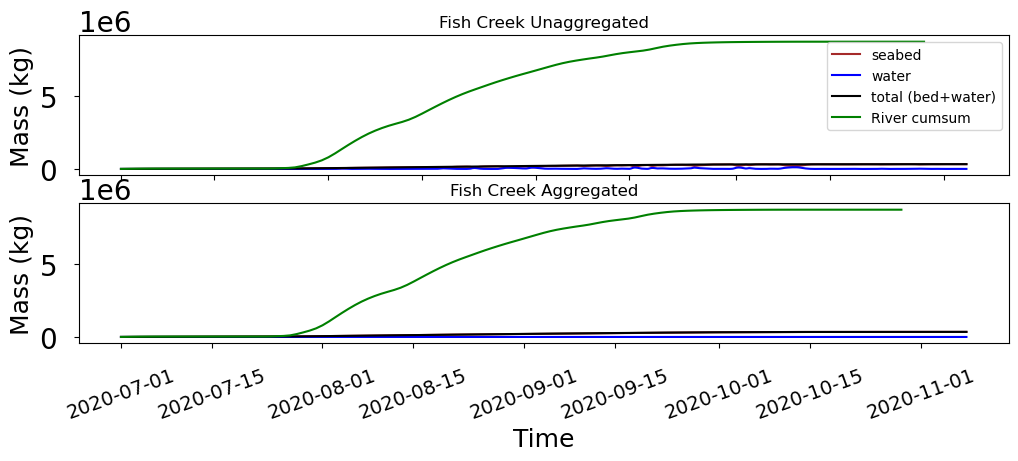

In [112]:
# Fish Creek
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.fis_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.fis_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.fis_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.fis_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, fis_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Fish Creek Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.fis_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.fis_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.fis_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.fis_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, fis_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Fish Creek Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

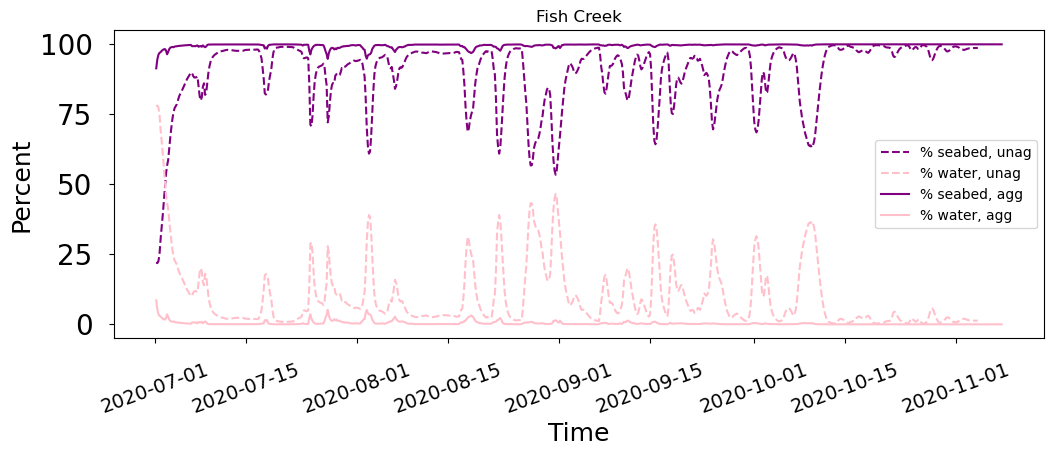

In [113]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Calculate total
fis_tot_from_output_unag = (river_sed_seabed_water_unag.fis_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.fis_tot_sed_water_unag_full)
fis_tot_from_output_agg = (river_sed_seabed_water_agg.fis_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.fis_tot_sed_water_agg_full)

# Fish Creek
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.fis_tot_sed_seabed_unag_full/fis_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.fis_tot_sed_water_unag_full/fis_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.fis_tot_sed_seabed_agg_full/fis_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.fis_tot_sed_water_agg_full/fis_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Fish Creek')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)

Text(0, 0.5, 'Mass (kg)')

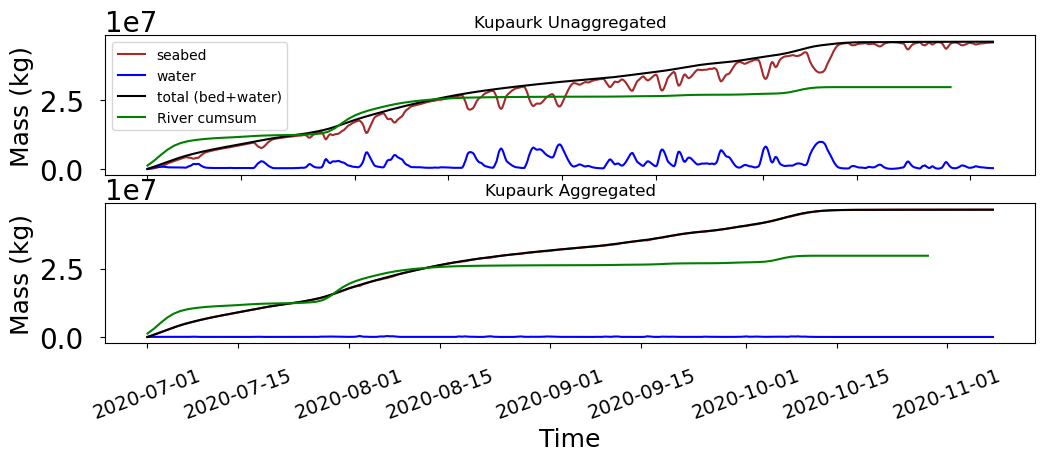

In [91]:
# Kuparuk
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kup_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kup_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.kup_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.kup_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, kup_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Kupaurk Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kup_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kup_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.kup_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.kup_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, kup_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Kupaurk Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

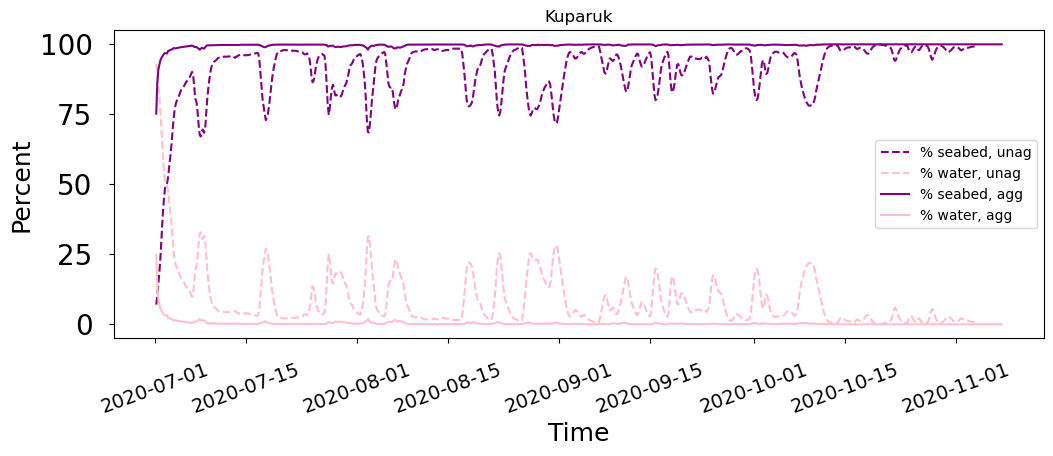

In [114]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Calculate total
kup_tot_from_output_unag = (river_sed_seabed_water_unag.kup_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.kup_tot_sed_water_unag_full)
kup_tot_from_output_agg = (river_sed_seabed_water_agg.kup_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.kup_tot_sed_water_agg_full)

# Kuparuk
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kup_tot_sed_seabed_unag_full/kup_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kup_tot_sed_water_unag_full/kup_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kup_tot_sed_seabed_agg_full/kup_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kup_tot_sed_water_agg_full/kup_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Kuparuk')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)

Text(0, 0.5, 'Mass (kg)')

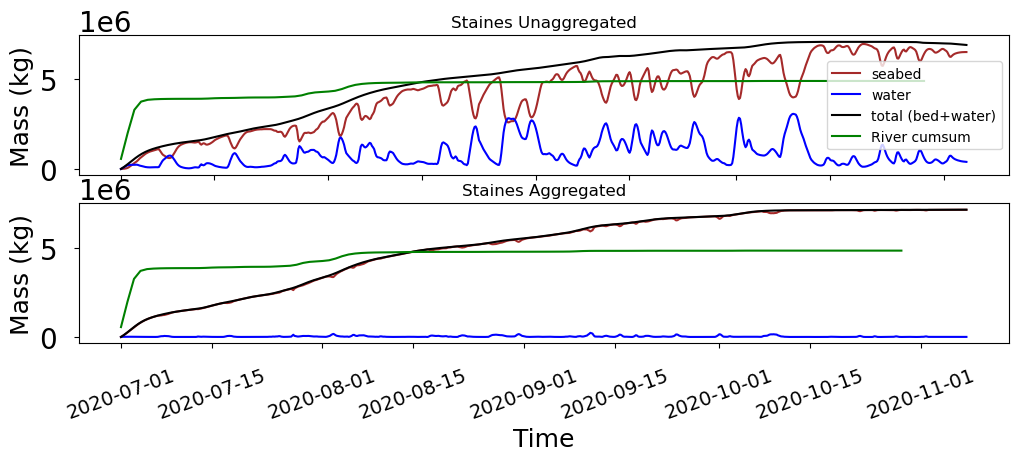

In [98]:
# Staines 
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.sta_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.sta_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.sta_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.sta_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, sta_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Staines Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.sta_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.sta_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.sta_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.sta_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, sta_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Staines Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

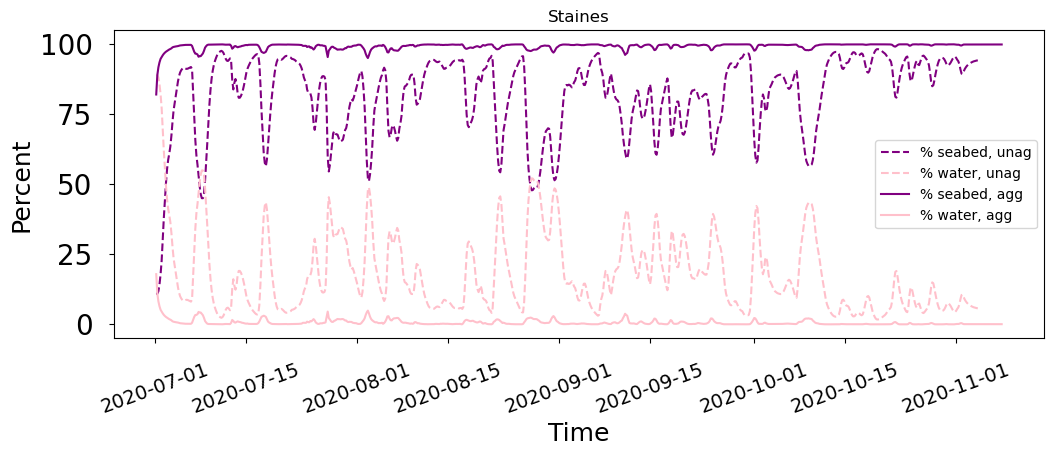

In [115]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Calculate total
sta_tot_from_output_unag = (river_sed_seabed_water_unag.sta_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.sta_tot_sed_water_unag_full)
sta_tot_from_output_agg = (river_sed_seabed_water_agg.sta_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.sta_tot_sed_water_agg_full)

# Staines
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.sta_tot_sed_seabed_unag_full/sta_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.sta_tot_sed_water_unag_full/sta_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.sta_tot_sed_seabed_agg_full/sta_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.sta_tot_sed_water_agg_full/sta_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Staines')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)

Text(0, 0.5, 'Mass (kg)')

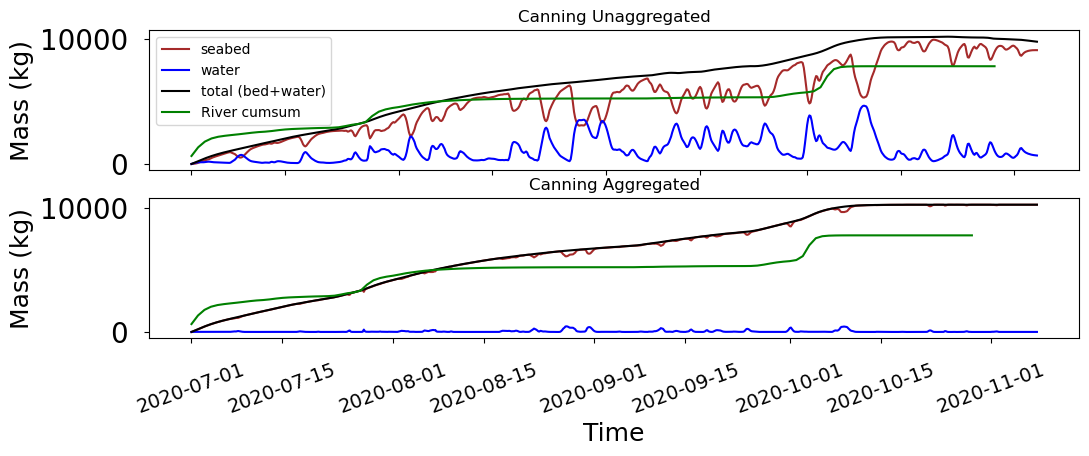

In [93]:
# Canning 
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.can_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.can_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.can_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.can_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, can_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Canning Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.can_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.can_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.can_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.can_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, can_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Canning Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

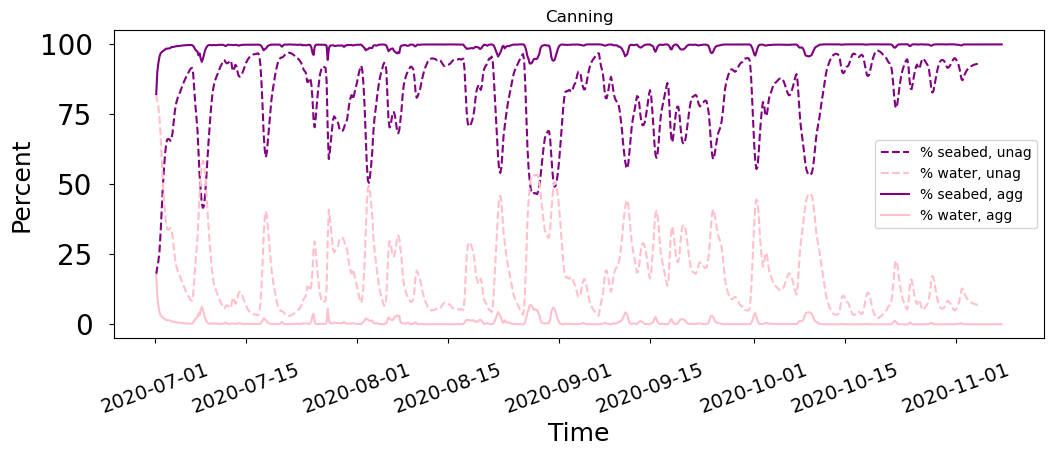

In [116]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Calculate total
can_tot_from_output_unag = (river_sed_seabed_water_unag.can_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.can_tot_sed_water_unag_full)
can_tot_from_output_agg = (river_sed_seabed_water_agg.can_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.can_tot_sed_water_agg_full)

# Canning
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.can_tot_sed_seabed_unag_full/can_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.can_tot_sed_water_unag_full/can_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.can_tot_sed_seabed_agg_full/can_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.can_tot_sed_water_agg_full/can_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Canning')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)

Text(0, 0.5, 'Mass (kg)')

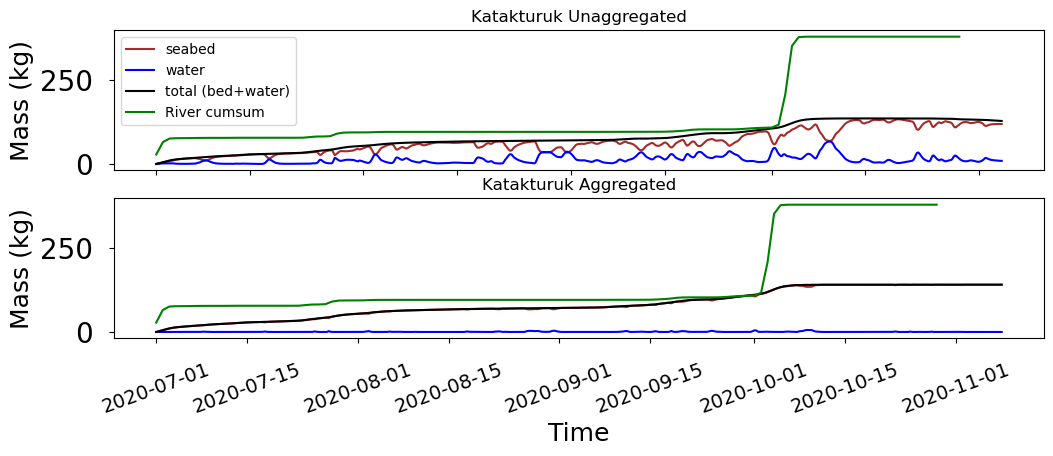

In [94]:
# Katakturuk
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kat_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kat_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.kat_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.kat_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, kat_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Katakturuk Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kat_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kat_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.kat_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.kat_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, kat_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Katakturuk Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

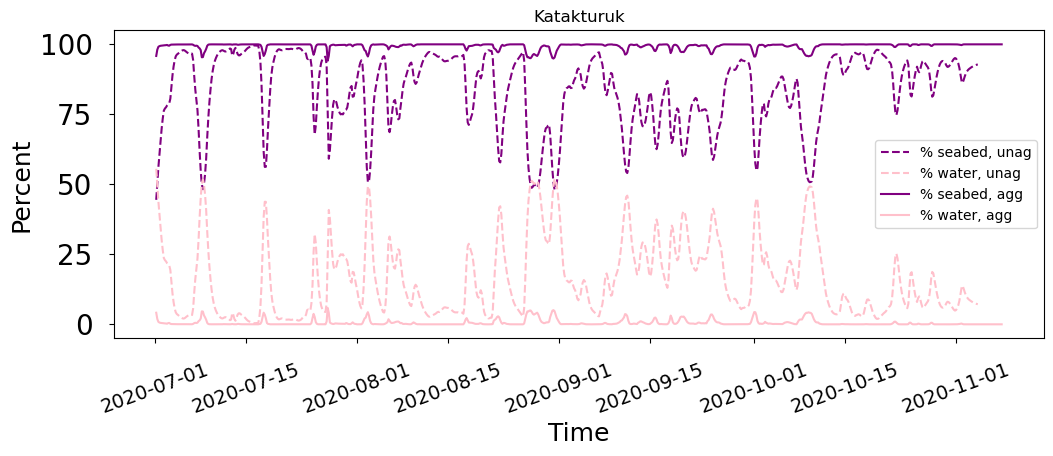

In [117]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Calculate total
kat_tot_from_output_unag = (river_sed_seabed_water_unag.kat_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.kat_tot_sed_water_unag_full)
kat_tot_from_output_agg = (river_sed_seabed_water_agg.kat_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.kat_tot_sed_water_agg_full)

# Katakturuk
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kat_tot_sed_seabed_unag_full/kat_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.kat_tot_sed_water_unag_full/kat_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kat_tot_sed_seabed_agg_full/kat_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.kat_tot_sed_water_agg_full/kat_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Katakturuk')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)

Text(0, 0.5, 'Mass (kg)')

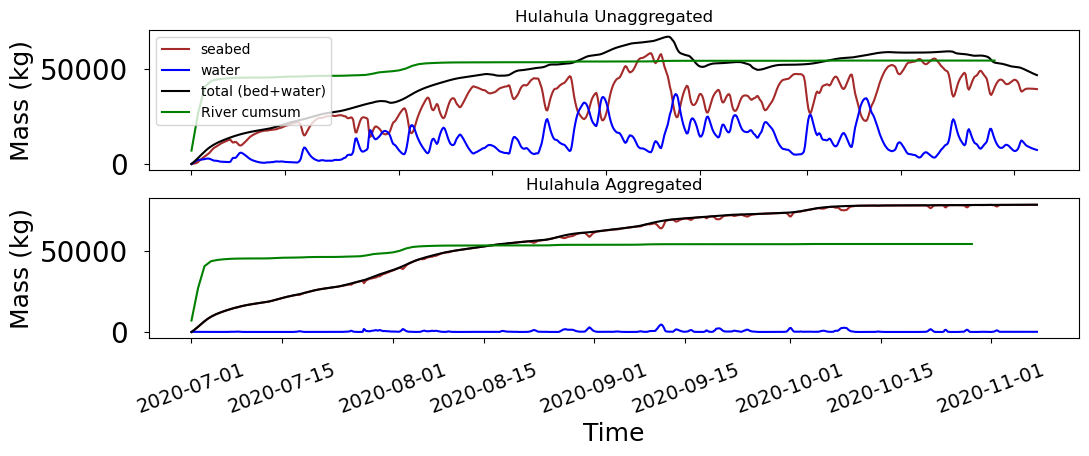

In [95]:
# Hulahula
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.hul_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.hul_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.hul_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.hul_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, hul_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Hulahula Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.hul_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.hul_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.hul_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.hul_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, hul_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Hulahula Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

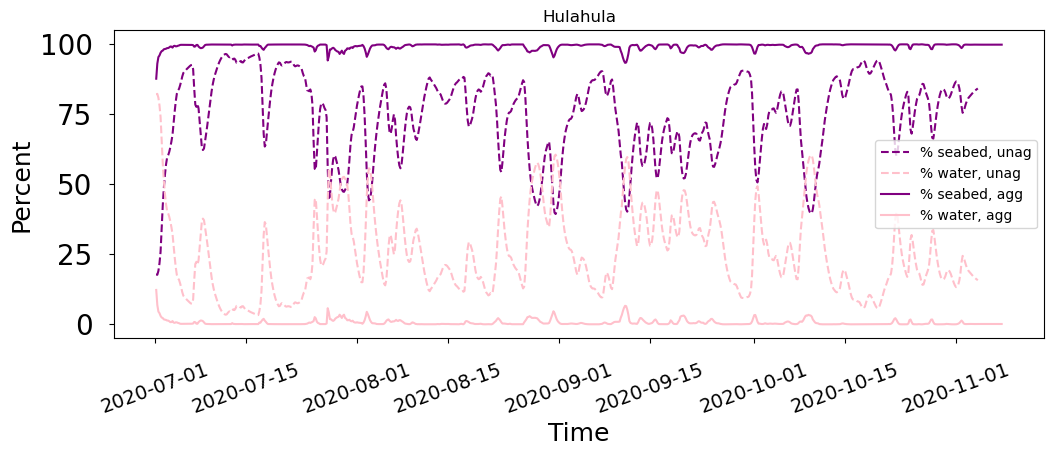

In [118]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Calculate total
hul_tot_from_output_unag = (river_sed_seabed_water_unag.hul_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.hul_tot_sed_water_unag_full)
hul_tot_from_output_agg = (river_sed_seabed_water_agg.hul_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.hul_tot_sed_water_agg_full)

# Hulahula
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.hul_tot_sed_seabed_unag_full/hul_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.hul_tot_sed_water_unag_full/hul_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.hul_tot_sed_seabed_agg_full/hul_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.hul_tot_sed_water_agg_full/hul_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Hulahula')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)

Text(0, 0.5, 'Mass (kg)')

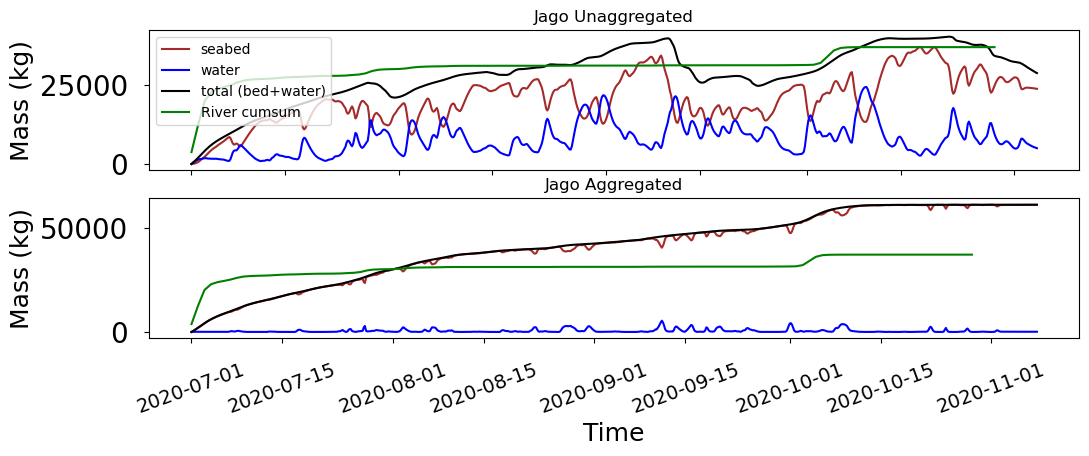

In [96]:
# Jago 
fig, ax = plt.subplots(2, figsize=(12,4))

# Unaggregated
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.jag_tot_sed_seabed_unag_full, color='brown', label='seabed')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.jag_tot_sed_water_unag_full, color='blue', label='water')
ax[0].plot(river_sed_seabed_water_unag.ocean_time.values, (river_sed_seabed_water_unag.jag_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.jag_tot_sed_water_unag_full), 
            color='black', label='total (bed+water)')
ax[0].plot(river_frc_std.river_time[:121].values, jag_tot_sed_kg, color='green', label='River cumsum')
ax[0].legend()
ax[0].set_title('Jago Unaggregated')
ax[0].set_xticklabels([])
#ax[0].set_xlabel('Time')
ax[0].set_ylabel('Mass (kg)', fontsize=fontsize-2)

# Aggregated 
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.jag_tot_sed_seabed_agg_full, color='brown', label='seabed')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.jag_tot_sed_water_agg_full, color='blue', label='water')
ax[1].plot(river_sed_seabed_water_agg.ocean_time.values, (river_sed_seabed_water_agg.jag_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.jag_tot_sed_water_agg_full), 
            color='black', label='total (bed+water)')
ax[1].plot(river_frc_std.river_time[:121].values, jag_tot_sed_kg, color='green', label='River cumsum')
ax[1].tick_params(axis='x', labelsize=14, rotation=20)
ax[1].set_title('Jago Aggregated')
ax[1].set_xlabel('Time', fontsize=fontsize-2)
ax[1].set_ylabel('Mass (kg)', fontsize=fontsize-2)

Text(0, 0.5, 'Percent')

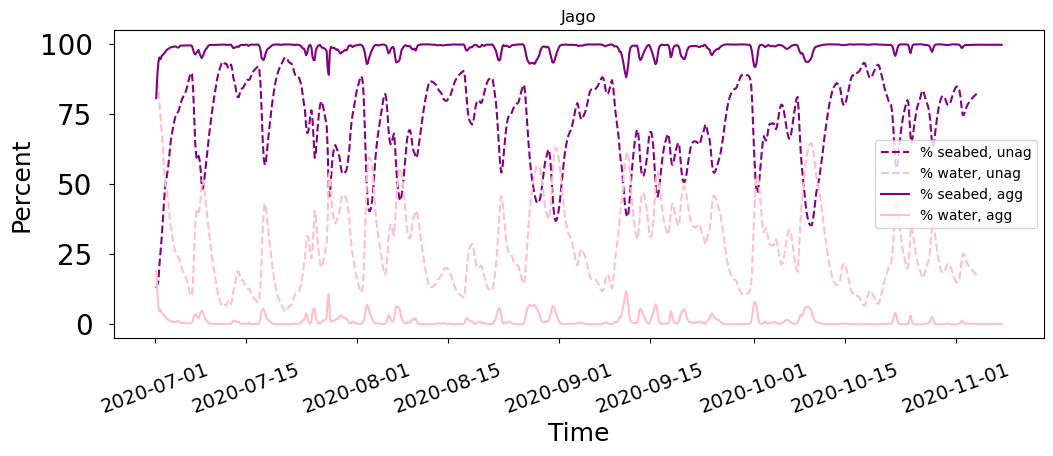

In [119]:
# Use the calculated total from amount in bed vs. water to
# plot percentages over time
# Calculate total
jag_tot_from_output_unag = (river_sed_seabed_water_unag.jag_tot_sed_seabed_unag_full + river_sed_seabed_water_unag.jag_tot_sed_water_unag_full)
jag_tot_from_output_agg = (river_sed_seabed_water_agg.jag_tot_sed_seabed_agg_full + river_sed_seabed_water_agg.jag_tot_sed_water_agg_full)

# Jago
fig, ax = plt.subplots(figsize=(12,4))

# Unaggregated
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.jag_tot_sed_seabed_unag_full/jag_tot_from_output_unag*100, color='purple', label='% seabed, unag', linestyle='--')
ax.plot(river_sed_seabed_water_unag.ocean_time.values, river_sed_seabed_water_unag.jag_tot_sed_water_unag_full/jag_tot_from_output_unag*100, color='pink', label='% water, unag', linestyle='--')
# Aggregated
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.jag_tot_sed_seabed_agg_full/jag_tot_from_output_agg*100, color='purple', label='% seabed, agg')
ax.plot(river_sed_seabed_water_agg.ocean_time.values, river_sed_seabed_water_agg.jag_tot_sed_water_agg_full/jag_tot_from_output_agg*100, color='pink', label='% water, agg')
ax.tick_params(axis='x', labelsize=14, rotation=20)
ax.legend()
ax.set_title('Jago')
ax.set_xlabel('Time', fontsize=fontsize-2)
ax.set_ylabel('Percent', fontsize=fontsize-2)